# Comparative Evaluation of ImageNet-Pretrained ResNet-18 and DeiT-Tiny for Pediatric Pneumonia Classification

## Full Fine-Tuning on PneumoniaMNIST+ 224

*A Study of Biomedical Image Classification and Transfer Learning*

**Author:** Victoria Tran (My-Uyen Tran)  
**Notebook:** `pneumoniamnist-cnn-transformer-uyentran.ipynb`

## Overview

This project presents a controlled educational comparison of an ImageNet-pretrained Convolutional Neural Network (CNN) and Vision Transformer (ViT) for binary pneumonia classification using the PneumoniaMNIST+ 224 dataset.

Two models, ResNet-18 and DeiT-Tiny, are fully fine-tuned on pediatric chest X-ray images under a shared training and evaluation protocol. Each model is trained independently using three random seeds (42, 43, 44), resulting in six training runs.

The study compares classification performance, variability across random seeds, and training time while examining how pretrained CNN and Transformer architectures can be adapted to a medical image classification task.

## Research Question

**How do ImageNet-pretrained ResNet-18 and DeiT-Tiny compare in pediatric pneumonia classification performance and training time under a shared full fine-tuning protocol?**

## Experimental Design

Two models are evaluated:

| Model | Architecture | Role |
|---|---|---|
| **E1 — ResNet-18** | ImageNet-pretrained CNN with residual connections | CNN baseline |
| **E2 — DeiT-Tiny** | ImageNet-pretrained Vision Transformer with 12 Transformer Encoder blocks and 3 attention heads | ViT comparison model |

Both models use pretrained ImageNet-1K weights and a new classification head with two output logits.

All model parameters, including the pretrained feature extractors and classification heads, are updated during full fine-tuning. No layers are frozen, and no custom weight initialization is applied.

ResNet-18 extracts visual features through convolutional and residual blocks. DeiT-Tiny divides each 224 × 224 image into 196 non-overlapping patches, adds a CLS token and positional embeddings, and processes the resulting 197 tokens through Transformer Encoder blocks.

Each model is trained independently with three predefined random seeds under the same hyperparameters, producing six training runs.

## Model Architecture Overview

The diagram below illustrates the data preprocessing pipeline, ResNet-18 and DeiT-Tiny architectures, intermediate tensor shapes, and shared full fine-tuning protocol.

![PneumoniaMNIST+ 224 — Model Architectures and Experimental Pipeline](../images/vision-transformer-pneumonia4.png)

Both models receive three-channel images with input shape `(B, 3, 224, 224)` and produce two raw classification logits with output shape `(B, 2)`, where `B` is the batch size.

For DeiT-Tiny, each image is represented by 196 patch tokens and one CLS token, with an embedding dimension of 192.

Total and trainable parameter counts are verified directly from the models in Part 2.

## Experimental Protocol & Evaluation

- **Dataset:** PneumoniaMNIST+ 224 — 5,856 grayscale pediatric chest X-ray images, two classes (Normal and Pneumonia), using the official splits: 4,708 training, 524 validation, and 624 test images.

- **Data inspection:** Dataset shapes, labels, class distribution table, bar chart, and four sample X-ray images.

- **Preprocessing:** Convert grayscale images to three channels, apply `ToTensor()` and ImageNet normalization (mean `[0.485, 0.456, 0.406]`, std `[0.229, 0.224, 0.225]`), without data augmentation.

- **Training:** Full fine-tuning with AdamW, learning rate `2e-5`, weight decay `0.01`, batch size 16, and unweighted CrossEntropyLoss.

- **Reproducibility:** Three predefined random seeds `[42, 43, 44]`. Each run starts with a fresh pretrained model, optimizer, and seeded training DataLoader.

- **Training duration:** Five fixed epochs per model per seed, resulting in six independent runs and 30 training epochs in total, without early stopping or learning-rate scheduling.

- **Model selection:** Save the best checkpoint for each model and seed based on validation macro-F1. Ties retain the earlier checkpoint.

- **Validation metrics:** Average loss and macro-F1 after each epoch.

- **Final test metrics:** Macro-F1 (primary), accuracy, sensitivity, specificity, and ROC-AUC, reported for each seed and summarized using mean ± standard deviation across three seeds.

- **Error analysis:** Examine false positives and false negatives across all six model–seed runs using confusion matrices for both models and all three seeds.  

- **Training outputs:** Six best checkpoints, training histories, loss curves, parameter counts, runtime measurements, and validation/test summary tables.

Both models follow the same fixed experimental settings, with independent initialization and training for each seed. The official test set is reserved for final evaluation after checkpoint selection.

The three-seed design provides a preliminary assessment of run-to-run variability. However, the small medical image dataset, limited number of seeds, and shared hyperparameters without model-specific tuning prevent strong conclusions about statistical significance or universal architectural superiority. The results are intended for educational research, not clinical use.

## Notebook Organization

- **Part 0 — Setup & Configuration:** Import libraries, define experiment settings, initialize random seeds and device, and prepare project directories.

- **Part 1 — Data Pipeline:** Load official dataset splits, inspect images and class distributions, apply shared preprocessing, and verify DataLoaders.

- **Part 2 — Pretrained Models & Architecture Inspection:** Load and verify ResNet-18 and DeiT-Tiny, examine their architectures, and inspect DeiT-Tiny tensor shapes.

- **Part 3 — Training & Validation Pipeline:** Define the classification loss, reusable training and validation functions, and validation-based checkpoint selection.

- **Part 4 — Full Fine-Tuning Experiments:**  

  - **4.1 — Define Experiment Configuration**  

  - **4.2 — Run Full Fine-Tuning Experiments**  

  - **4.3 — Validation Summary & Seed Decision**

- **Part 5 — Final Test Evaluation & Model Comparison:** Evaluate validation-selected checkpoints on the held-out test set, summarize results across seeds, and analyze classification errors.

- **Part 6 — Discussion & Conclusion:** Interpret the comparison, discuss variability and limitations, and summarize the main findings.

---  


## Part 0 — Setup & Reproducibility

### Overview & Objective

Import the required libraries, define the shared experimental configuration, and initialize the computation device and random seeds for reproducible model training and evaluation.

### Workflow & Section Guide

- **0.1 — Imports & Device Selection:** Import libraries, select MPS or CPU, and record environment information.
- **0.2 — Experimental Configuration, Random Seeds & Output Directories:** Define fixed training settings, configure three random seeds, and prepare project directories for saving experimental results.

### Important Objects & Their Roles

- `cfg`: Stores the shared experimental settings using `@dataclass Config`.  

- `cfg.seeds`: Defines three random seeds `[42, 43, 44]` for independent training runs.  

- `cfg.learning_rate`, `cfg.batch_size`, `cfg.epochs`: Store fixed training settings shared by ResNet-18 and DeiT-Tiny.  

- `set_seed()`: Initializes Python, NumPy, and PyTorch random-number generators for each run.  

- `device`: Selects MPS when available, otherwise CPU.  

- `cfg.project_root`, `cfg.images_dir`: Provide project-relative paths for organizing data, figures, results, and checkpoints.

### Connections to Subsequent Parts

Parts 1–5 reuse the shared configuration, device, and project directories. Part 4 resets the random seed before each independent training run.

Both models use the same fixed training configuration across three seeds. No model-specific hyperparameter tuning or custom weight initialization is performed.

### Expected Outcome & Role in the Experiment

A consistent experimental setup supporting six independent full fine-tuning runs (2 models × 3 seeds), with reproducible random initialization and training sample shuffling.

---

### 0.1 — Imports & Device Selection

**Objective**

Import the required Python libraries, select the computation device, and record the software environment.

**Purpose**

Prepare the tools needed for data processing, pretrained model fine-tuning, and evaluation. Recording library versions helps document the environment used in the experiments.

**Procedure**

1. Import standard Python libraries for random seeds, timing, and file management.  

2. Import NumPy, Pandas, and Matplotlib for data analysis and visualization.  

3. Import PyTorch, torchvision, timm, and MedMNIST for image preprocessing and model training.  
 
4. Import scikit-learn metrics for validation and final evaluation.  

5. Select Apple Silicon MPS if available; otherwise, use CPU.  

6. Display the Python and library versions and the selected device.

**Expected Results**

- All required libraries are imported successfully.  

- The selected computation device (`mps` or `cpu`) is displayed.  

- Python, PyTorch, timm, and MedMNIST versions are recorded.

**Role in the Experiment**

The selected `device` is reused for model training, validation, and testing in subsequent parts.

---

In [ ]:
%pip install torch torchvision timm medmnist scikit-learn matplotlib pandas numpy

# Import standard Python tools for reproducibility, timing, and file management.
import random                           
import sys                               
print(sys.executable)
import time                             
from pathlib import Path                
from importlib.metadata import version  
from dataclasses import dataclass, field  
import math
import json

# Import libraries for numerical operations, data tables, and visualization.
import numpy as np                      
import pandas as pd                     
import matplotlib.pyplot as plt          
from matplotlib.ticker import MaxNLocator  

# Import PyTorch tools for building, training, and evaluating neural networks.
import torch                            
import torch.nn as nn                   
import torch.optim as optim             
from torch.utils.data import DataLoader  
import torchvision
from torchvision import transforms      
from torchvision.utils import make_grid
from torch.utils.data import TensorDataset

# Import pretrained models and the PneumoniaMNIST dataset.
import timm                             # Load ImageNet-pretrained ResNet-18 and DeiT-Tiny models.
from medmnist import PneumoniaMNIST, INFO  

# Import evaluation metrics for classification performance and error analysis.
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score  
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay 

# Select the best available computation device for PyTorch.
if torch.cuda.is_available():
    device = torch.device("cuda")      
elif torch.backends.mps.is_available():
    device = torch.device("mps")       
else:
    device = torch.device("cpu")       

# Record the software environment for reproducibility.
print("Python version:", sys.version.split()[0])  
print("PyTorch version:", torch.__version__)      
print("timm version:", timm.__version__)           
print("MedMNIST version:", version("medmnist"))    
print("Device:", device)                          


Note: you may need to restart the kernel to use updated packages.
/opt/anaconda3/bin/python
Python version: 3.13.5
PyTorch version: 2.14.1
timm version: 1.0.31
MedMNIST version: 3.0.2
Device: mps


### 0.2 — Experimental Configuration, Random Seeds & Output Directories

**Objective**

Define the shared training configuration, initialize the random seed, and prepare directories for saving experimental outputs.

**Purpose**

Keep the training settings consistent across ResNet-18 and DeiT-Tiny, improve reproducibility, and organize project files without hardcoded paths.

**Procedure**

1. Define the fixed settings: image size, number of classes, three random seeds `[42, 43, 44]`, batch size, learning rate, weight decay, epochs, and DataLoader workers.  

2. Define `set_seed()` to initialize Python, NumPy, and PyTorch random-number generators, and apply seed 42 for initial notebook setup.  

3. Locate the project directory and create folders for figures, results, and model checkpoints.  

4. Display the configuration and output paths for verification.

**Important Distinctions**

- Both models use AdamW, CrossEntropyLoss, and the same fixed learning rate (`2e-5`) for five epochs per seed. No model-specific hyperparameter tuning is performed.  

- The best checkpoint is selected separately for each model and seed using validation macro-F1, not automatically from the final epoch.  

- Pretrained model weights are loaded without custom weight initialization.  

- Random seeds improve reproducibility but do not guarantee fully deterministic GPU operations.

**Expected Results**

- Shared experimental settings are initialized.  

- Three random seeds `[42, 43, 44]` are configured, with seed 42 applied initially.  

- Output directories are created.  

- Configuration values and directory paths are displayed.

**Role in the Experiment**

Parts 1–5 reuse these settings. Part 4 resets the random seed before each of the six independent training runs.

  


In [ ]:
# Define the fixed experimental settings shared by both pretrained models.
SEEDS = [42, 43, 44]  
IMAGE_SIZE = 224        
NUM_CLASSES = 2         
BATCH_SIZE = 16         
LEARNING_RATE = 2e-5    
WEIGHT_DECAY = 0.01     
EPOCHS = 5             
NUM_WORKERS = 0         

# Locate the working project directory.
def find_project_root() -> Path:
    current_dir = Path.cwd().resolve()                                      

    # Search for the directory containing notebooks/ and data/.
    for folder in (current_dir, *current_dir.parents):                      
        if (folder / "notebooks").is_dir() and (folder / "data").is_dir():  
            return folder                                                   

    # For a standalone notebook, use the current working directory.
    return current_dir  


# Group shared experiment settings and project paths in one configuration class.
@dataclass
class Config:
    seeds: list[int] = field(default_factory=lambda: SEEDS.copy())  
    image_size: int = IMAGE_SIZE           
    num_classes: int = NUM_CLASSES         
    batch_size: int = BATCH_SIZE           
    learning_rate: float = LEARNING_RATE   
    weight_decay: float = WEIGHT_DECAY     
    epochs: int = EPOCHS                   
    num_workers: int = NUM_WORKERS         

    project_root: Path = field(default_factory=find_project_root)  

    @property
    def images_dir(self) -> Path:
        return self.project_root / "images"  # Store model diagrams, dataset visualizations, and evaluation figures.

    @property
    def results_dir(self) -> Path:
        return self.project_root / "results"  # Store evaluation tables and CSV files.

    @property
    def checkpoint_dir(self) -> Path:
        return self.project_root / "checkpoints"  # Store best validation-selected model weights.

# Set Python, NumPy, and PyTorch random seeds to improve reproducibility.
def set_seed(seed: int) -> None:
    random.seed(seed)          
    np.random.seed(seed)       
    torch.manual_seed(seed)    


# Initialize the configuration and apply the first random seed.
cfg = Config()                 
set_seed(cfg.seeds[0])         # Apply seed 42; reset the seed before each model run in Part 4.


# Create output directories without deleting existing files.
for folder in (cfg.images_dir, cfg.results_dir, cfg.checkpoint_dir):
    folder.mkdir(parents=True, exist_ok=True)  



# Display the main experiment settings and project path for verification.
print("Random seeds:", cfg.seeds)                    
print("Training:", f"LR={cfg.learning_rate}, Weight decay={cfg.weight_decay}, "
      f"Epochs={cfg.epochs}, Batch size={cfg.batch_size}")  
print("Data:", f"Image size={cfg.image_size}, Classes={cfg.num_classes}, "
      f"Workers={cfg.num_workers}")                 
print("Project root:", cfg.project_root)             
print("Output directories: images/, results/, checkpoints/")  



Random seeds: [42, 43, 44]
Training: LR=2e-05, Weight decay=0.01, Epochs=5, Batch size=16
Data: Image size=224, Classes=2, Workers=0
Project root: /Users/utmbpblack25/Documents/WorkingProjects
Output directories: images/, results/, checkpoints/


## Part 1 — Data Pipeline

### Overview & Objectives

Load and inspect the official PneumoniaMNIST+ 224 dataset, perform basic exploratory data analysis (EDA), and prepare a shared data pipeline for ImageNet-pretrained ResNet-18 and DeiT-Tiny.

This part covers dataset inspection, class distribution analysis, image preprocessing, DataLoader construction, and mini-batch verification.

### Workflow & Section Guide

- **1.1 — Load Official Dataset & Define Preprocessing:** Retrieve dataset metadata, define shared grayscale-to-RGB conversion and ImageNet normalization, and load the official training, validation, and test splits.  

- **1.2 — Dataset Inspection & Exploratory Data Analysis:** Inspect image properties and labels, calculate and visualize class distributions, display four training X-rays, and document dataset provenance.  

- **1.3 — Create DataLoaders & Verify Training Batch:** Construct DataLoaders for all three splits and verify mini-batch tensor shapes and data types.

### Important Objects & Their Roles

- `INFO`: Provides PneumoniaMNIST metadata, including task information and class labels.  

- `PneumoniaMNIST`: Loads images and labels from the official dataset splits.  

- `shared_transform`: Converts grayscale images to three channels, transforms them into PyTorch tensors, and applies ImageNet normalization.  

- `train_dataset`, `val_dataset`, `test_dataset`: Store the official datasets with the shared preprocessing transformation.  

- `train_loader`, `val_loader`, `test_loader`: Provide mini-batches for training, validation, and final testing.  


### Connections to Subsequent Parts

The verified data pipeline provides consistent input tensors for ResNet-18 and DeiT-Tiny in Part 2 and supports model training, validation, and final evaluation in Parts 3–5.

### Expected Outcomes & Role in the Experiment

A validated PneumoniaMNIST+ 224 data pipeline containing:

- Verified dataset metadata, class labels, and official split sizes: 4,708 training, 524 validation, and 624 test images. 

- A class distribution table, a grouped bar chart, and four labeled training X-rays. 

- Shared grayscale-to-RGB conversion and ImageNet normalization, without data augmentation. 

- Three DataLoaders with batch size 16, shuffling enabled only for training. 

- Verified mini-batch shapes: images `(B, 3, 224, 224)` with dtype `torch.float32` and labels `(B,)` with dtype `torch.int64` after reshaping.

This pipeline ensures both pretrained models use the same official dataset splits and deterministic preprocessing for a controlled comparison.

---

### 1.1 — Load Official Dataset & Define Preprocessing

**Objective:** Load the official PneumoniaMNIST+ 224 dataset splits and define a shared preprocessing pipeline for ImageNet-pretrained ResNet-18 and DeiT-Tiny.

**Purpose:** Ensure both models receive consistently preprocessed images while preserving the official dataset splits.

**Procedure:**

1. Retrieve PneumoniaMNIST metadata, including the classification task, class labels, original image channels, and official split sizes.  

2. Define `shared_transform` to convert grayscale images to three channels, scale pixel values to [0, 1], and apply ImageNet normalization.  

3. Load the official training, validation, and test datasets using the same transformation.  

4. Verify the number of samples in each split against the dataset metadata.

**Expected Results:**

- Official dataset sizes: 4,708 training, 524 validation, and 624 test images.  

- Two class labels: Normal (0) and Pneumonia (1).  

- Original images: single-channel grayscale X-rays at 224 × 224 resolution.  

- Shared preprocessing: `Grayscale(3) → ToTensor() → Normalize(ImageNet mean/std)`.  

- All three official dataset splits loaded and verified.

**Important Distinction:** `ToTensor()` scales pixel values to [0, 1], while `Normalize()` standardizes each channel using ImageNet mean and standard deviation. The resulting normalized values are not restricted to [0, 1]. No data augmentation or training-derived normalization is used.


In [ ]:
# Retrieve official PneumoniaMNIST metadata and display its basic specifications.
info = INFO["pneumoniamnist"]   

print("Dataset:", info["python_class"])
print("Task:", info["task"])
print("Original image channels:", info["n_channels"])
print("Number of classes:", len(info["label"]))
print("Official split sizes:", info["n_samples"])

# Display the two class labels in numerical order.
print("\nClass labels:")
for class_id in sorted(info["label"], key=int):   # Sort class IDs numerically (0, 1), rather than alphabetically.
    print(f"  {class_id}: {info['label'][class_id]}")


# Define one shared preprocessing pipeline for both ImageNet-pretrained models.
shared_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),    
    transforms.ToTensor(),                          
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],                 
        std=[0.229, 0.224, 0.225]                   
    )
])

# Store the dataset in the shared project data directory.
DATA_DIR = cfg.project_root / "data"                 


# Load the three official dataset splits with identical preprocessing.
train_dataset = PneumoniaMNIST(
    split="train",                                  
    root=str(DATA_DIR),                             
    size=cfg.image_size,                            
    transform=shared_transform,                    
    download=True                                   
)

val_dataset = PneumoniaMNIST(
    split="val",                                    
    root=str(DATA_DIR),
    size=cfg.image_size,
    transform=shared_transform,
    download=True
)

test_dataset = PneumoniaMNIST(
    split="test",                                   
    root=str(DATA_DIR),
    size=cfg.image_size,
    transform=shared_transform,
    download=True
)


# Verify the number of images in each official dataset split.
print("\nOfficial dataset sizes:")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

assert len(train_dataset) == info["n_samples"]["train"]   
assert len(val_dataset) == info["n_samples"]["val"]       
assert len(test_dataset) == info["n_samples"]["test"]     




Dataset: PneumoniaMNIST
Task: binary-class
Original image channels: 1
Number of classes: 2
Official split sizes: {'train': 4708, 'val': 524, 'test': 624}

Class labels:
  0: normal
  1: pneumonia


100%|██████████| 214M/214M [03:03<00:00, 1.17MB/s] 



Official dataset sizes:
Training samples: 4708
Validation samples: 524
Test samples: 624


### 1.2 — Dataset Inspection & Exploratory Data Analysis

**Objective:** Inspect PneumoniaMNIST+ 224 image and label properties, examine class distributions, and visualize representative training images.

**Purpose:** Verify the dataset structure and identify class imbalance or distribution differences that may affect model evaluation.

**Procedure:**

1. Inspect original image arrays and labels across the three official splits, including shapes, data types, and pixel ranges. Verify the transformed shape and data type of one training image.  

2. Calculate Normal and Pneumonia class counts and percentages for each split, and summarize them in a Pandas DataFrame.  

3. Create a grouped bar chart comparing class percentages across training, validation, and test splits.  

4. Display four training X-rays: two Normal and two Pneumonia images.  

5. Document dataset provenance and its implications for interpreting model performance.

**Expected Results:**

- Verified grayscale image properties, transformed tensor shape `(3, 224, 224)`, and label formats.  

- One class distribution table covering all three official splits.  

- One grouped bar chart saved as `class_distribution.png`.  

- Four labeled training X-rays saved as `sample_xrays.png`.  

- A brief description of dataset provenance and observed class imbalance.

**Dataset Provenance:** PneumoniaMNIST is derived from an existing pediatric chest X-ray dataset. The official training and validation splits are derived from the source development data, while the 624-image test split is held out for final evaluation. Differences in class proportions and data provenance may influence validation and test performance.

**Important Distinction:** Original images are inspected and visualized before normalization to preserve their grayscale appearance. The test split is included in descriptive dataset analysis but is not used for training, checkpoint selection, or hyperparameter decisions.


In [ ]:
# Organize the official datasets for consistent inspection and later EDA.
datasets = {
    "Train": train_dataset,
    "Validation": val_dataset,
    "Test": test_dataset
}

# Inspect original image properties and label formats before preprocessing.
for split_name, dataset in datasets.items():
    images = dataset.imgs                  
    labels = dataset.labels                

    print(f"\n{split_name} dataset:")
    print("  Images (shape, dtype):", images.shape, images.dtype)
    print("  Pixel range:", images.min(), images.max())  
    print("  Labels (shape, dtype):", labels.shape, labels.dtype)


# Inspect one training sample after applying the shared preprocessing.
sample_tensor, sample_label = train_dataset[0]  

print("\nPreprocessed training sample:")
print("  Image (shape, dtype):", sample_tensor.shape, sample_tensor.dtype)
print("  Pixel range:", sample_tensor.min().item(), sample_tensor.max().item()) 
print("  Label (value, shape):", sample_label, np.asarray(sample_label).shape)  

# Compare one training image before and after shared preprocessing.
sample_array = train_dataset.imgs[0]               
sample_tensor, sample_label = train_dataset[0]      

print("\nOriginal training sample:")
print("  Shape:", sample_array.shape)              
print("  Dtype:", sample_array.dtype)              
print("  Pixel range:", sample_array.min(), sample_array.max())

print("\nPreprocessed training sample:")
print("  Shape:", tuple(sample_tensor.shape))      
print("  Dtype:", sample_tensor.dtype)             
print("  Pixel range:", sample_tensor.min().item(), sample_tensor.max().item())

print("\nSample label:")
print("  Value:", sample_label)                    # Class 0 (Normal) or 1 (Pneumonia).
print("  Shape:", np.asarray(sample_label).shape)  .


# Verify that the preprocessed image is compatible with both pretrained models.
assert sample_tensor.shape == (3, cfg.image_size, cfg.image_size)  
assert sample_tensor.dtype == torch.float32                        



Train dataset:
  Images (shape, dtype): (4708, 224, 224) uint8
  Pixel range: 0 255
  Labels (shape, dtype): (4708, 1) uint8

Validation dataset:
  Images (shape, dtype): (524, 224, 224) uint8
  Pixel range: 0 255
  Labels (shape, dtype): (524, 1) uint8

Test dataset:
  Images (shape, dtype): (624, 224, 224) uint8
  Pixel range: 0 255
  Labels (shape, dtype): (624, 1) uint8

Preprocessed training sample:
  Image (shape, dtype): torch.Size([3, 224, 224]) torch.float32
  Pixel range: -2.1179039478302 2.395991325378418
  Label (value, shape): [1] (1,)

Original training sample:
  Shape: (224, 224)
  Dtype: uint8
  Pixel range: 0 241

Preprocessed training sample:
  Shape: (3, 224, 224)
  Dtype: torch.float32
  Pixel range: -2.1179039478302 2.395991325378418

Sample label:
  Value: [1]
  Shape: (1,)


PneumoniaMNIST+ 224 — Class Distribution:


,Normal,Pneumonia,Total,Pneumonia (%)
Split,,,,
Train,1214,3494,4708,74.21
Validation,135,389,524,74.24
Test,234,390,624,62.50


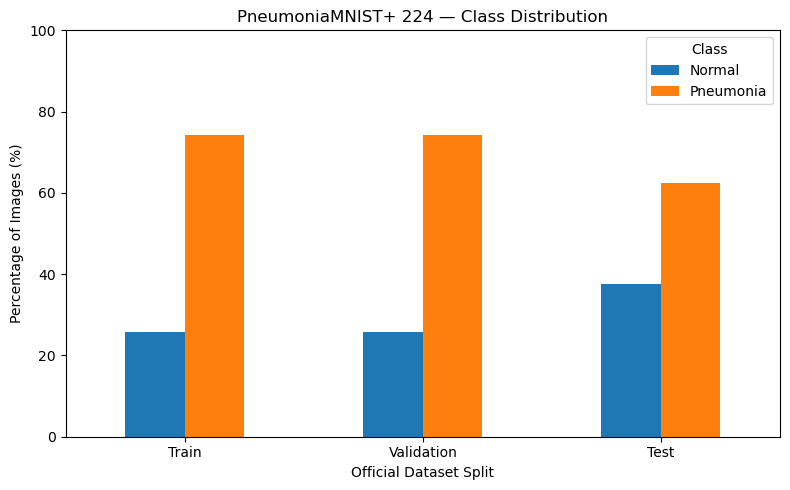

In [ ]:
# Calculate class counts and percentages for the three official dataset splits.
distribution_rows = []

for split_name, dataset in datasets.items():
    labels = dataset.labels.reshape(-1).astype(int)  
    counts = np.bincount(labels, minlength=2)        

    distribution_rows.append({
        "Split": split_name,
        "Normal": counts[0],                         
        "Pneumonia": counts[1],                      
        "Total": len(labels),                        
        "Pneumonia (%)": round(100 * counts[1] / len(labels), 2)
    })

# Summarize the class distribution in one Pandas DataFrame.
class_distribution = pd.DataFrame(distribution_rows).set_index("Split")

print("PneumoniaMNIST+ 224 — Class Distribution:")
display(class_distribution)


# Convert class counts to percentages to compare splits of different sizes.
class_percentages = class_distribution[["Normal", "Pneumonia"]].div(
    class_distribution["Total"], axis=0             
) * 100

# Create a grouped bar chart showing both class percentages for each split.
ax = class_percentages.plot.bar(figsize=(8, 5), rot=0)  

ax.set_title("PneumoniaMNIST+ 224 — Class Distribution")
ax.set_xlabel("Official Dataset Split")
ax.set_ylabel("Percentage of Images (%)")
ax.set_ylim(0, 100)                                 
ax.legend(title="Class")

fig = ax.get_figure()                               
fig.tight_layout()                                  
fig.savefig(cfg.images_dir / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


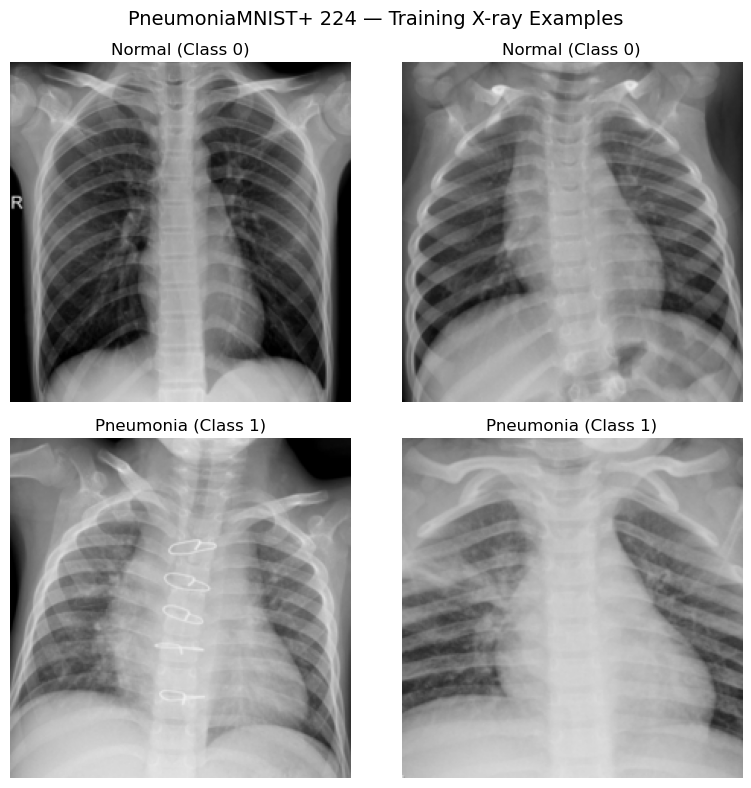

In [ ]:
# Select two training images from each class for visualization.
train_labels = train_dataset.labels.reshape(-1)       

normal_indices = np.where(train_labels == 0)[0][:2]   
pneumonia_indices = np.where(train_labels == 1)[0][:2] 

sample_indices = list(normal_indices) + list(pneumonia_indices)

assert len(sample_indices) == 4                         # Confirm that two images were found for each class.

# Display the original grayscale X-rays in a 2 × 2 grid.
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, image_index in zip(axes.flat, sample_indices):
    image = train_dataset.imgs[image_index]             
    class_id = int(train_labels[image_index])           
    class_name = info["label"][str(class_id)].capitalize()

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)     
    ax.set_title(f"{class_name} (Class {class_id})")    
    ax.axis("off")                                      

fig.suptitle("PneumoniaMNIST+ 224 — Training X-ray Examples", fontsize=14)
fig.tight_layout()
fig.savefig(cfg.images_dir / "sample_xrays.png", dpi=150, bbox_inches="tight")
plt.show()


### 1.2 — Results & Interpretation

**Implementation & Verification**

- Verified the original image shapes, data types, pixel ranges, and label formats across all three official dataset splits.
- Confirmed that shared preprocessing converts grayscale images from `(224, 224)` with `uint8` pixels into normalized `torch.float32` tensors with shape `(3, 224, 224)`.

**Results & Key Observations**

- **Class Distribution:** Pneumonia is the majority class in all three splits, accounting for 74.21% of training images, 74.24% of validation images, and 62.50% of test images.  

- **Split Differences:** Training and validation have nearly identical class proportions, while the test set has a lower Pneumonia proportion by approximately 11.7 percentage points.  

- **Image Visualization:** The four displayed X-rays illustrate examples from both classes. These images are illustrative and do not represent the full variability within each class.

**Interpretation**

The observed class imbalance supports using macro-F1 as the primary evaluation metric, since it gives equal weight to both classes. Differences in class proportions and dataset provenance may influence validation and test performance, so results should be interpreted carefully. The shared preprocessing provides consistent model inputs for ResNet-18 and DeiT-Tiny.

---  


### 1.3 — Create DataLoaders & Verify Training Batch

**Objective:** Create DataLoaders for the three official dataset splits and verify that training mini-batches have the correct tensor shapes and data types.

**Purpose:** Prepare a consistent mini-batch pipeline for training, validation, and final evaluation of ResNet-18 and DeiT-Tiny.

**Procedure:**

1. Create training, validation, and test DataLoaders using batch size 16 and `num_workers=0`, with shuffling enabled only for training.  

2. Verify the number of mini-batches in each DataLoader.
3. Retrieve one training mini-batch and reshape labels to `(B,)` with `torch.int64` dtype for `CrossEntropyLoss`.  

4. Inspect image shapes, data types, class IDs, and normalized pixel ranges. Verify the essential tensor properties.

**Expected Results:**

- Three DataLoaders using the shared ImageNet preprocessing defined in Section 1.1.  

- Training batches shuffled reproducibly; validation and test batches unshuffled.  

- Image tensor shape `(16, 3, 224, 224)` with `torch.float32` dtype.  

- Label tensor shape `(16,)` with `torch.int64` dtype and class IDs 0 or 1.  

- Verified model inputs with finite normalized pixel values.

**Important Distinction:** The test DataLoader is created here but will only be used for final evaluation in Part 5. Training and checkpoint selection use the training and validation splits, respectively.


In [ ]:
# Create a fresh training DataLoader with reproducible sample shuffling.
def make_train_loader(seed: int) -> DataLoader:
    generator = torch.Generator().manual_seed(seed)  

    return DataLoader(
        train_dataset,                       
        batch_size=cfg.batch_size,           
        shuffle=True,                        
        generator=generator,                 
        num_workers=cfg.num_workers          
    )


# Initialize the training loader and create validation/test loaders.
train_loader = make_train_loader(cfg.seeds[0])  

val_loader = DataLoader(
    val_dataset,                             
    batch_size=cfg.batch_size,
    shuffle=False,                           
    num_workers=cfg.num_workers
)

test_loader = DataLoader(
    test_dataset,                            
    batch_size=cfg.batch_size,
    shuffle=False,                           
    num_workers=cfg.num_workers
)


# Display the number of mini-batches in each DataLoader.
print("Number of batches:")
print("  Train:", len(train_loader))
print("  Validation:", len(val_loader))
print("  Test:", len(test_loader))


# Retrieve one training mini-batch and prepare labels for CrossEntropyLoss.
images, labels = next(iter(train_loader))    
labels = labels.view(-1).long()              


# Inspect tensor shapes, data types, class IDs, and normalized pixel values.
print("\nTraining mini-batch:")
print("  Images shape:", tuple(images.shape))  
print("  Images dtype:", images.dtype)         
print("  Labels shape:", tuple(labels.shape))  
print("  Labels dtype:", labels.dtype)         
print("  Class IDs:", torch.unique(labels).tolist())  
print("  Pixel range:", images.min().item(), images.max().item())  # Normalized values may fall outside [0, 1].


# Verify the essential tensor properties before model construction and training.
assert images.shape[1:] == (3, cfg.image_size, cfg.image_size)  
assert images.dtype == torch.float32                          
assert labels.shape == (images.shape[0],)                       
assert labels.dtype == torch.long                               
assert torch.all((labels >= 0) & (labels < cfg.num_classes))    
assert torch.isfinite(images).all()                             



Number of batches:
  Train: 295
  Validation: 33
  Test: 39

Training mini-batch:
  Images shape: (16, 3, 224, 224)
  Images dtype: torch.float32
  Labels shape: (16,)
  Labels dtype: torch.int64
  Class IDs: [0, 1]
  Pixel range: -2.1179039478302 2.640000104904175


## Part 2 — Pretrained Models & Architecture Inspection

### Overview & Objectives

Load and inspect ImageNet-pretrained ResNet-18 and DeiT-Tiny for binary pneumonia classification using the `timm` library.

This part covers pretrained model loading, classification head configuration, parameter inspection, full fine-tuning verification, and the key architectural components of DeiT-Tiny.

### Workflow & Section Guide

- **2.1 — Load & Verify Pretrained Models:** Load ResNet-18 and DeiT-Tiny with two output classes, verify classification logits and parameter counts, and confirm that all model parameters are trainable.  

- **2.2 — Understand DeiT-Tiny Architecture:** Explain patch embedding, CLS token, positional embedding, multi-head self-attention, and Transformer Encoder blocks.  

- **2.3 — Verify DeiT-Tiny Tensor Shapes:** Inspect patch embeddings, token representations, and classification logits to verify the expected data flow through DeiT-Tiny.

### Important Objects & Their Roles

- `timm.create_model()`: Loads pretrained model architectures and configures their classification heads.  

- `resnet18.tv_in1k`: ImageNet-1K-pretrained ResNet-18 (CNN).  

- `deit_tiny_patch16_224.fb_in1k`: ImageNet-1K-pretrained DeiT-Tiny (Vision Transformer).  

- `num_classes=2`: Configures each model to output two classification logits for Normal and Pneumonia.  

- `model.parameters()`: Provides model parameters for counting total/trainable parameters and verifying full fine-tuning.  

- `patch_embed`, `pos_embed`, `forward_features()`: Support inspection of DeiT-Tiny's patch embeddings, positional embeddings, and Transformer Encoder output.

### Connections to Subsequent Parts

The verified model architectures establish the foundation for the shared training and validation functions in Part 3.

Part 4 will initialize fresh pretrained models and full fine-tune them using the same training protocol. Part 5 will evaluate their validation-selected checkpoints on the official test set.

### Expected Outcomes & Role in the Experiment

Two verified pretrained classification models with:

- ImageNet-1K pretrained weights and classification heads configured for two classes.  

- Verified total and trainable parameter counts, with all model parameters available for full fine-tuning.  

- Classification output logits with shape `(B, 2)` for both models.  

- Verified DeiT-Tiny architecture: 196 image patches, 197 tokens including CLS, embedding dimension 192, 12 Transformer Encoder blocks, and 3 attention heads.  

- Verified DeiT-Tiny tensor shapes: patch embeddings `(B, 196, 192)`, encoded token representations `(B, 197, 192)`, and classification logits `(B, 2)`.

This part confirms that both pretrained architectures are correctly configured for the shared full fine-tuning experiments.

---

### 2.1 — Load & Verify Pretrained Models

**Objective:** Load ImageNet-pretrained ResNet-18 and DeiT-Tiny, configure their classification heads for two classes, and verify their output shapes and trainable parameters.

**Purpose:** Ensure both pretrained models are correctly configured and ready for full fine-tuning on PneumoniaMNIST+ 224.

**Procedure:**

1. Load ResNet-18 (`resnet18.tv_in1k`) and DeiT-Tiny (`deit_tiny_patch16_224.fb_in1k`) using `timm.create_model()` with `pretrained=True` and `num_classes=2`.  

2. Perform a forward pass using a small batch of preprocessed training images and verify that both models produce logits with shape `(B, 2)`.  

3. Calculate the total and trainable parameter counts for each model.  

4. Verify that all model parameters remain trainable for full fine-tuning.  

5. Summarize the model configurations and parameter counts in one comparison table.

**Expected Results:**

- Two ImageNet-pretrained models with classification heads configured for Normal and Pneumonia.  

- Output logits with shape `(B, 2)` for both models.  

- Verified total and trainable parameter counts.  

- All model parameters available for full fine-tuning.

**Important Distinction:** `pretrained=True` loads ImageNet-pretrained weights, while `num_classes=2` configures a new classification head for the target task. The pretrained feature extractors remain trainable. No model weights are updated during architecture inspection.


In [ ]:
# Load both ImageNet-pretrained models with two output classes.
resnet18 = timm.create_model(
    "resnet18.tv_in1k",                        
    pretrained=True,                          
    num_classes=cfg.num_classes                
).to(device)

deit_tiny = timm.create_model(
    "deit_tiny_patch16_224.fb_in1k",           
    pretrained=True,
    num_classes=cfg.num_classes                
).to(device)


# Organize both models for consistent architecture verification.
models = {
    "ResNet-18": resnet18,
    "DeiT-Tiny": deit_tiny
}

inspection_images = images[:2].to(device)      # Use two preprocessed training images from Section 1.3.
model_results = []                             


# Verify classification outputs and parameter counts for each model.
for model_name, model in models.items():
    model.eval()                               

    with torch.no_grad():                      
        logits = model(inspection_images)      # Forward pass: (B, 3, 224, 224) -> (B, 2).

    total_params = sum(p.numel() for p in model.parameters())  
    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad  
    )

    # Confirm the expected classification output and full fine-tuning configuration.
    assert logits.shape == (len(inspection_images), cfg.num_classes)
    assert trainable_params == total_params    # Ensure no encoder or classification-head parameters are frozen.

    model_results.append({
        "Model": model_name,
        "Output Shape": tuple(logits.shape),   
        "Total Parameters": total_params,
        "Trainable Parameters": trainable_params
    })


# Display one comparison table for the two pretrained models.
model_summary = pd.DataFrame(model_results).set_index("Model")

print("Pretrained Model Verification:")
display(model_summary)

print("\nBoth pretrained models passed architecture and parameter verification.")


Pretrained Model Verification:


,Output Shape,Total Parameters,Trainable Parameters
Model,,,
ResNet-18,"(2, 2)",11177538,11177538
DeiT-Tiny,"(2, 2)",5524802,5524802



Both pretrained models passed architecture and parameter verification.


### 2.2 — Understand DeiT-Tiny Architecture

**Objective:** Understand the main architectural components of DeiT-Tiny and how an input image is processed for binary classification.

**Architecture Overview**

DeiT-Tiny is a Vision Transformer (ViT) that divides an image into patches and uses Transformer Encoder blocks to learn relationships between them.

| Component | Configuration |
|---|---|
| Input Image | 224 × 224 × 3 |
| Patch Size | 16 × 16 |
| Patch Tokens | 196 (14 × 14) |
| CLS Token | 1 |
| Total Tokens | 197 |
| Embedding Dimension | 192 |
| Transformer Encoder Blocks | 12 |
| Attention Heads | 3 |
| Features per Head | 64 |
| Classification Output | 2 logits |

**Architecture Workflow**

1. **Patch Embedding:** Divide the input image into 196 non-overlapping patches (16 × 16 pixels each). Convert each patch into a 192-dimensional embedding vector.

2. **CLS Token & Positional Embedding:** Add one learnable CLS token to the 196 patch tokens, producing 197 tokens. Add positional embeddings to provide information about token positions.

3. **Transformer Encoder:** Process the 197 tokens through 12 Transformer Encoder blocks. Each block contains multi-head self-attention, an MLP, LayerNorm, and residual connections. Self-attention uses 3 heads, each operating on 64-dimensional features.

4. **Classification Head:** Use the final CLS token representation to produce two logits, corresponding to Normal (0) and Pneumonia (1).

**Connection to Section 2.3**

The next section verifies the expected tensor shapes using the pretrained DeiT-Tiny model:

- Input images: `(B, 3, 224, 224)`  

- Patch embeddings: `(B, 196, 192)`  

- Token representations: `(B, 197, 192)`  

- Classification logits: `(B, 2)`

The pretrained architecture is provided by `timm`; no custom implementation of attention or Transformer Encoder blocks is required.

### 2.3 — Verify DeiT-Tiny Tensor Shapes

**Objective:** Verify the tensor shapes at key stages of the pretrained DeiT-Tiny architecture.

**Purpose:** Connect the architecture described in Section 2.2 with actual PyTorch tensor outputs.

**Procedure:**

1. Reuse the pretrained DeiT-Tiny and two preprocessed training images from Section 2.1.  

2. Inspect the patch embeddings produced by `patch_embed`.  

3. Verify the shapes of the CLS token and positional embeddings.  

4. Use `forward_features()` to inspect the token representations after the Transformer Encoder.  

5. Use `forward_head()` to obtain classification logits and verify the expected tensor shapes.

**Expected Results:**

- Input images: `(B, 3, 224, 224)`.  

- Patch embeddings: `(B, 196, 192)`.  

- CLS token: `(1, 1, 192)`.  

- Positional embeddings: `(1, 197, 192)`.  

- Encoded token representations: `(B, 197, 192)`.  

- Classification logits: `(B, 2)`.

**Important Distinction:** `patch_embed` produces only patch embeddings, while `forward_features()` includes CLS token insertion, positional embeddings, and Transformer Encoder processing. `forward_head()` converts the encoded representation into classification logits.


In [ ]:
# Inspect DeiT-Tiny using the same preprocessed images from Section 2.1.
deit_tiny.eval()                              

with torch.no_grad():                         
    patch_embeddings = deit_tiny.patch_embed(inspection_images)  # Convert images into 196 patch embeddings.
    encoded_tokens = deit_tiny.forward_features(inspection_images)  # Process 197 tokens through the Transformer Encoder.
    logits = deit_tiny.forward_head(encoded_tokens)  # Convert the final CLS representation into two logits.


# Display tensor shapes at key stages of the DeiT-Tiny architecture.
print("DeiT-Tiny Tensor Shapes:")
print("  Input images:", tuple(inspection_images.shape))
print("  Patch embeddings:", tuple(patch_embeddings.shape))
print("  CLS token:", tuple(deit_tiny.cls_token.shape))
print("  Positional embeddings:", tuple(deit_tiny.pos_embed.shape))
print("  Encoded tokens:", tuple(encoded_tokens.shape))
print("  Classification logits:", tuple(logits.shape))


# Verify the expected tensor dimensions for the DeiT-Tiny architecture.
B = inspection_images.shape[0]                # Number of images in the inspection batch.

assert patch_embeddings.shape == (B, 196, 192)  # 196 patches, each represented by 192 features.
assert deit_tiny.cls_token.shape == (1, 1, 192)  # One learnable CLS token shared across images.
assert deit_tiny.pos_embed.shape == (1, 197, 192)  # Positional embeddings for 196 patches + 1 CLS token.
assert encoded_tokens.shape == (B, 197, 192)  # Final representations of all 197 tokens.
assert logits.shape == (B, cfg.num_classes)   # Two output logits: Normal and Pneumonia.

print("\nDeiT-Tiny tensor shape verification passed.")


DeiT-Tiny Tensor Shapes:
  Input images: (2, 3, 224, 224)
  Patch embeddings: (2, 196, 192)
  CLS token: (1, 1, 192)
  Positional embeddings: (1, 197, 192)
  Encoded tokens: (2, 197, 192)
  Classification logits: (2, 2)

DeiT-Tiny tensor shape verification passed.


### Part 2 — Results & Verification

- **Model Configuration:** Both pretrained models produce logits with shape `(2, 2)`. ResNet-18 has 11,177,538 parameters, while DeiT-Tiny has 5,524,802 parameters. All parameters are trainable for full fine-tuning.  

- **DeiT-Tiny Architecture:** Verified 196 patch embeddings, 197 encoded tokens including CLS, and an embedding dimension of 192. The classification head produces two logits per image.

Both models passed the required architecture checks and are ready for the training pipeline. Actual model performance will be evaluated in Parts 4–5.

---  


## Part 3 — Training & Validation Pipeline

### Overview & Objectives

Develop a shared PyTorch training and validation pipeline for full fine-tuning ImageNet-pretrained ResNet-18 and DeiT-Tiny on PneumoniaMNIST+ 224.

This part defines the loss function, reusable training and validation functions, and a training loop with validation-based checkpoint selection.

### Workflow & Section Guide

- **3.1 — Define Loss & Training Function:** Define `CrossEntropyLoss` and implement `train_one_epoch()` to update model parameters and calculate average training loss.  

- **3.2 — Define Validation Function:** Implement `validate()` to calculate validation loss and macro-F1 without updating model parameters.  

- **3.3 — Define Training Loop & Checkpoint Selection:** Implement `train_model()` to train for five epochs, record training history, and save the best checkpoint based on validation macro-F1.

### Important Objects & Their Roles

- `nn.CrossEntropyLoss()`: Calculates classification loss from two output logits and integer class labels.  

- `torch.optim.AdamW`: Updates model parameters during training, with a separate optimizer initialized for each model in Part 4.  

- `train_loader`: Provides shuffled training mini-batches.  

- `val_loader`: Provides validation mini-batches for performance monitoring and checkpoint selection.  

- `train_one_epoch()`: Performs forward propagation, backpropagation, and optimizer updates for one epoch.  

- `validate()`: Computes validation loss and macro-F1 without updating model parameters.  

- `train_model()`: Coordinates training and validation across epochs, records results, and saves the best checkpoint.

### Connections to Subsequent Parts

Part 4 uses these shared functions to independently fine-tune ResNet-18 and DeiT-Tiny under the same training configuration.

Part 5 evaluates the best validation-selected checkpoints on the official held-out test set.

### Expected Outcomes & Role in the Experiment

A reusable training and validation pipeline containing:

- `CrossEntropyLoss` for binary classification with two output logits.  

- `train_one_epoch()` returning sample-weighted average training loss.  

- `validate()` returning sample-weighted average validation loss and macro-F1.  

- `train_model()` managing five training epochs, recording training history and runtime, and selecting the best checkpoint by validation macro-F1.  

- A consistent training procedure applicable to both pretrained models.  

This pipeline supports a controlled model comparison while keeping training, validation, and final test evaluation separate.

---

### 3.1 — Define Loss & Training Function

**Objective:** Define the classification loss and implement a reusable function to train either pretrained model for one epoch.

**Purpose:** Establish a consistent training procedure for ResNet-18 and DeiT-Tiny using standard PyTorch operations.

**Procedure:**

1. Define `nn.CrossEntropyLoss()` for binary classification with two output logits.  

2. Implement `train_one_epoch()` to:
   - Set the model to training mode using `model.train()`.  

   - Iterate through training mini-batches and move images and labels to the selected device.  

   - Reshape labels to `(B,)` and convert them to `torch.int64`.  

   - Perform forward propagation and calculate the batch loss.  

   - Reset gradients, perform backpropagation, and update model parameters using the optimizer.  

   - Accumulate batch losses weighted by the number of samples.  

3. Return the sample-weighted average training loss across the entire epoch.

**Expected Results:**

- A shared `CrossEntropyLoss` function for both pretrained models.  

- A reusable `train_one_epoch()` function that updates model parameters and returns average training loss.

**Important Distinction:** `CrossEntropyLoss` accepts raw logits directly, without applying Softmax. The optimizer will be initialized separately for each model in Part 4. Training loss is averaged by sample count because the final mini-batch may contain fewer than 16 images.


In [ ]:
# Define the classification loss shared by ResNet-18 and DeiT-Tiny.
criterion = nn.CrossEntropyLoss()  


# Train a model for one epoch and return its average training loss.
def train_one_epoch(model, loader, criterion, optimizer, device):
    """Train the model for one epoch and return the sample-weighted average loss."""

    model.train()                      
    total_loss = 0.0                   
    total_samples = 0                  

    for images, labels in loader:
        # Prepare the mini-batch for model training.
        images = images.to(device)                 
        labels = labels.view(-1).long().to(device) 

        # Perform forward propagation, backpropagation, and parameter updates.
        optimizer.zero_grad()          
        logits = model(images)         # Forward pass: (B, 3, 224, 224) -> (B, 2).
        loss = criterion(logits, labels) 
        loss.backward()               
        optimizer.step()              

        # Accumulate loss weighted by the actual batch size.
        batch_size = images.size(0)    
        total_loss += loss.item() * batch_size  
        total_samples += batch_size    

    return total_loss / total_samples  


### 3.2 — Define Validation Function

**Objective:** Implement a reusable `validate()` function to calculate validation loss and macro-F1 without updating model parameters.

**Purpose:** Monitor model performance on the validation set and provide macro-F1 scores for checkpoint selection.

**Procedure:**

1. Set the model to evaluation mode using `model.eval()` and disable gradient tracking with `torch.no_grad()`.  

2. Iterate through validation mini-batches and move images and labels to the selected device.  

3. Reshape labels to `(B,)` with `torch.int64` dtype.  

4. Perform forward propagation, calculate batch loss, and obtain predicted class IDs using `argmax()`.  

5. Accumulate sample-weighted validation loss and collect true and predicted labels across all batches.  

6. Calculate macro-F1 using `sklearn.metrics.f1_score()` and return both validation metrics.

**Expected Results:**

- A reusable `validate()` function returning:  

  - Sample-weighted average validation loss.  

  - Validation macro-F1 across Normal and Pneumonia classes.  
  
- Model parameters remain unchanged during validation.

**Important Distinction:** Unlike `train_one_epoch()`, `validate()` does not perform backpropagation or optimizer updates. Validation macro-F1 is used to select the best checkpoint in Section 3.3, while the official test set remains reserved for Part 5.


In [ ]:
# Evaluate a model on the validation set without updating its parameters.
def validate(model, loader, criterion, device):
    """Return sample-weighted average validation loss and macro-F1."""

    model.eval()                       
    total_loss = 0.0                   
    total_samples = 0                  
    all_labels = []                    
    all_predictions = []               

    with torch.no_grad():              
        for images, labels in loader:
            # Prepare the validation mini-batch.
            images = images.to(device)                  
            labels = labels.view(-1).long().to(device)  

            # Perform forward propagation and calculate validation loss.
            logits = model(images)                      # Forward pass: (B, 3, 224, 224) -> (B, 2).
            loss = criterion(logits, labels)            
            predictions = logits.argmax(dim=1)         

            # Accumulate loss weighted by the actual number of images.
            batch_size = images.size(0)                 
            total_loss += loss.item() * batch_size      
            total_samples += batch_size                 

            # Collect labels and predictions for dataset-level macro-F1.
            all_labels.extend(labels.cpu().tolist())          
            all_predictions.extend(predictions.cpu().tolist()) 

    # Calculate validation metrics across the entire dataset.
    avg_val_loss = total_loss / total_samples                 
    val_macro_f1 = f1_score(all_labels, all_predictions, average="macro")  

    return avg_val_loss, val_macro_f1


### 3.3 — Define Training Loop & Checkpoint Selection

**Objective:** Implement a reusable `train_model()` function to manage training, validation, and checkpoint selection across five epochs.

**Purpose:** Apply the same training procedure to ResNet-18 and DeiT-Tiny while selecting model checkpoints based on validation performance.

**Procedure:**

1. Initialize training history and the best validation macro-F1 score.  

2. For each epoch:  

   - Call `train_one_epoch()` to update model parameters and calculate training loss.  
    
   - Call `validate()` to calculate validation loss and macro-F1.  

   - Record the three metrics in training history.  

   - Save the model checkpoint when validation macro-F1 improves.  

3. Measure the total training duration.  

4. Return training history, best epoch, best validation macro-F1, and training duration.

**Expected Results:**

- A reusable `train_model()` function for both pretrained models.  

- Training history containing training loss, validation loss, and validation macro-F1 for each epoch.  

- A saved checkpoint from the epoch with the highest validation macro-F1.  

- Recorded best epoch, best validation macro-F1, and training duration.

**Important Distinction:** Checkpoint selection uses only validation macro-F1. If two epochs achieve the same score, the earlier checkpoint is retained. All five epochs are completed, and the test set is not used during training or model selection.


In [ ]:
# Train a model across multiple epochs and save the best validation checkpoint.
def train_model(model, train_loader, val_loader, criterion, optimizer, device, epochs, checkpoint_path):
    """Train the model and return its history, best checkpoint metrics, and runtime."""

    history = {
        "train_loss": [],                      
        "val_loss": [],                        
        "val_macro_f1": []                     
    }

    best_val_macro_f1 = -1.0                   # Start below the minimum possible F1 score (0).
    best_epoch = 0                             # Store the epoch with the highest validation macro-F1.

    # Start timing after completing any pending MPS operations.
    if device.type == "mps":
        torch.mps.synchronize()                # Wait for previously submitted GPU operations to finish.
    start_time = time.perf_counter()           # Record the start time for the training run.

    # Train and validate the model for the configured number of epochs.
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )                                      # Update model weights and return average training loss.

        val_loss, val_macro_f1 = validate(
            model, val_loader, criterion, device
        )                                      # Evaluate the model without updating weights.

        # Record training and validation metrics for this epoch.
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_macro_f1"].append(val_macro_f1)

        # Save the model only when validation macro-F1 strictly improves.
        if val_macro_f1 > best_val_macro_f1:
            best_val_macro_f1 = val_macro_f1   # Update the highest validation macro-F1 observed.
            best_epoch = epoch                 # Record the epoch corresponding to the best score.
            torch.save(model.state_dict(), checkpoint_path)  # Save the best model weights.

        print(
            f"Epoch {epoch}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Macro-F1: {val_macro_f1:.4f}"
        )

    # Measure the completed training run, including validation and checkpoint saving.
    if device.type == "mps":
        torch.mps.synchronize()                
    training_duration = time.perf_counter() - start_time

    return history, best_epoch, best_val_macro_f1, training_duration


## Part 4 — Full Fine-Tuning Experiments

### Overview & Objectives

Full fine-tune ImageNet-pretrained ResNet-18 and DeiT-Tiny on PneumoniaMNIST+ 224 using the shared training and validation pipeline from Part 3.

This part runs six independent training experiments (2 models × 3 seeds) under the same training configuration, records training histories and runtimes, and selects the best checkpoint for each model and seed based on validation macro-F1.

### Workflow & Section Guide

- **4.1 — Define Experiment Configuration:** Specify the pretrained model IDs, use three predefined random seeds `[42, 43, 44]` from `cfg.seeds`, and prepare checkpoint paths for each model and seed.

- **4.2 — Run Full Fine-Tuning Experiments:** Use a shared experiment loop to initialize a fresh pretrained model, seeded training DataLoader, and AdamW optimizer for each run; train for five epochs; save the best checkpoint, training history, and runtime.

- **4.3 — Validation Summary & Seed Confirmation:** Compare best validation macro-F1, best epochs, and training runtimes across six runs. Summarize validation macro-F1 using mean and standard deviation across three seeds for each model.

### Important Objects & Their Roles

- `model_specs`: Maps ResNet-18 and DeiT-Tiny to their pretrained `timm` model IDs.

- `cfg.seeds`: Defines the three predefined random seeds `[42, 43, 44]` used for independent training runs.

- `set_seed()`: Resets random-number generators before each model run.

- `make_train_loader(seed)`: Creates a fresh training DataLoader with reproducible sample shuffling.

- `torch.optim.AdamW`: Initializes a separate optimizer for each model and seed using the shared learning rate and weight decay.

- `train_model()`: Runs training and validation, selects the best checkpoint, and returns training history, best epoch, best validation macro-F1, and runtime.

- `experiment_results`: Stores the results of all completed training runs for comparison and subsequent evaluation.

### Connections to Subsequent Parts

Part 5 loads the best validation-selected checkpoint from each of the six training runs and evaluates it on the official held-out test set.

Training histories are also used to visualize training and validation loss curves.

### Expected Outcomes & Role in the Experiment

Six completed full fine-tuning runs containing:

- ResNet-18 and DeiT-Tiny each trained independently for five epochs using seeds 42, 43, and 44.

- A shared training configuration: batch size 16, AdamW, learning rate `2e-5`, and weight decay `0.01`.

- Training loss, validation loss, and validation macro-F1 recorded for every epoch of each run.

- Six best checkpoints selected by the highest validation macro-F1, retaining the earlier epoch in case of a tie.

- Recorded best epochs and training runtimes for all six runs.

- A per-run validation summary and mean ± standard deviation of best validation macro-F1 across three seeds for each model.

The six training runs use the same experimental protocol, with random seeds reset independently before each run. The official test set remains excluded from training and checkpoint selection.

---

### 4.1 — Define Experiment Configuration

**Objective:** Define the pretrained models, random seeds, and checkpoint paths for the full fine-tuning experiments.

**Purpose:** Organize independent model runs and ensure each experiment saves its best checkpoint without overwriting checkpoints from other models or seeds.

**Procedure:**

1. Define `model_specs` containing the two pretrained model IDs: `resnet18.tv_in1k` and `deit_tiny_patch16_224.fb_in1k`.  

2. Use `cfg.seeds = [42, 43, 44]` and the shared training hyperparameters defined in Part 0.  

3. Prepare the project-relative `checkpoints/` directory.  

4. Define checkpoint filenames that identify each model and random seed.

**Expected Results:**

- Two pretrained models configured for six independent training runs (2 models × 3 seeds).  

- Three predefined random seeds: 42, 43, and 44.  

- A checkpoint directory available for saving model weights.  

- Six unique checkpoint filenames following the pattern `{model_name}_seed{seed}_best.pth`, such as `resnet18_seed42_best.pth` and `deit_tiny_seed44_best.pth`.

**Important Distinction:** This section only defines the experiment configuration. Fresh pretrained models, optimizers, and training DataLoaders will be initialized for each run in Section 4.2.

In [ ]:
# Define the two ImageNet-pretrained models for the experiments.
model_specs = {
    "resnet18": "resnet18.tv_in1k",                     
    "deit_tiny": "deit_tiny_patch16_224.fb_in1k"        
}

# Prepare the project directory for saving the best model checkpoints.
CHECKPOINT_DIR = cfg.project_root / "checkpoints"       
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)       


# Display the shared training configuration defined in Part 0.
print("Experiment configuration:")
print("  Models:", len(model_specs))
print("  Seeds:", cfg.seeds)                            # Three predefined seeds: 42, 43, and 44.
print("  Total runs:", len(model_specs) * len(cfg.seeds))
print("  Epochs per run:", cfg.epochs)
print("  Batch size:", cfg.batch_size)
print("  Learning rate:", cfg.learning_rate)
print("  Weight decay:", cfg.weight_decay)


# Display the planned checkpoint filename for each model and seed.
print("\nPlanned checkpoints:")

for model_name, model_id in model_specs.items():
    for seed in cfg.seeds:
        checkpoint_path = CHECKPOINT_DIR / f"{model_name}_seed{seed}_best.pth"  

        print(f"  {model_name} (seed {seed}): {checkpoint_path.name}")


Experiment configuration:
  Models: 2
  Seeds: [42, 43, 44]
  Total runs: 6
  Epochs per run: 5
  Batch size: 16
  Learning rate: 2e-05
  Weight decay: 0.01

Planned checkpoints:
  resnet18 (seed 42): resnet18_seed42_best.pth
  resnet18 (seed 43): resnet18_seed43_best.pth
  resnet18 (seed 44): resnet18_seed44_best.pth
  deit_tiny (seed 42): deit_tiny_seed42_best.pth
  deit_tiny (seed 43): deit_tiny_seed43_best.pth
  deit_tiny (seed 44): deit_tiny_seed44_best.pth


### 4.2 — Run Full Fine-Tuning Experiments

**Objective:** Full fine-tune ImageNet-pretrained ResNet-18 and DeiT-Tiny using the shared training pipeline and experimental configuration.

**Purpose:** Train both models independently under the same protocol and record their validation performance, best checkpoints, and training runtimes.

**Procedure:**

1. Iterate through the pretrained models in `model_specs` and random seeds in `cfg.seeds`.

2. For each run:
   - Reset the random seed and create a fresh training DataLoader.  

   - Load a fresh ImageNet-pretrained model with two output classes.  

   - Initialize a new AdamW optimizer using the shared learning rate and weight decay.  

   - Call `train_model()` to train for five epochs, validate after each epoch, and save the best checkpoint.  

   - Record training history, best epoch, validation macro-F1, and runtime.  

   - Save training history to CSV and release unused model objects before the next run.

3. Store the completed experiment results for comparison in Section 4.3.

**Expected Results:**

- Six independent full fine-tuning runs (2 models × 3 seeds: 42, 43, 44).  

- Training loss, validation loss, and validation macro-F1 recorded across five epochs per run.  

- Six best checkpoints selected using validation macro-F1.  

- Six training history CSV files and measured runtimes for all runs.  

- An `experiment_results` collection containing six runs for subsequent comparison and evaluation.

**Important Distinction:** Every run starts with fresh pretrained weights, a new optimizer, and a separately seeded training DataLoader. Only training data updates model weights; validation data selects the best checkpoint. The test set is not used in this section.

In [ ]:
# Prepare storage for experiment results and training histories.
experiment_results = []                             
RESULTS_DIR = cfg.project_root / "results"            
RESULTS_DIR.mkdir(parents=True, exist_ok=True)       


# Run each pretrained model independently for every configured random seed.
for model_name, model_id in model_specs.items():
    for seed in cfg.seeds:
        print(f"\nTraining {model_name} | Seed {seed}")

        # Initialize a fresh training run with reproducible sample shuffling.
        set_seed(seed)                                
        run_train_loader = make_train_loader(seed)    # Create a new DataLoader with its own seeded generator.

        model = timm.create_model(
            model_id,                                 # Load the selected ResNet-18 or DeiT-Tiny architecture.
            pretrained=True,                        
            num_classes=cfg.num_classes             
        ).to(device)

        optimizer = torch.optim.AdamW(
            model.parameters(),                       
            lr=cfg.learning_rate,                     
            weight_decay=cfg.weight_decay             
        )

        # Train for five epochs and save the best validation-selected checkpoint.
        checkpoint_path = CHECKPOINT_DIR / f"{model_name}_seed{seed}_best.pth"

        history, best_epoch, best_val_macro_f1, training_duration = train_model(
            model, run_train_loader, val_loader, criterion, optimizer, device,
            epochs=cfg.epochs,
            checkpoint_path=checkpoint_path
        )

        # Save the training history so results remain available after restarting the notebook.
        history_df = pd.DataFrame(history)             
        history_df.insert(0, "epoch", range(1, len(history_df) + 1))  
        history_path = RESULTS_DIR / f"{model_name}_seed{seed}_history.csv"
        history_df.to_csv(history_path, index=False)    

        # Record the completed run for validation summary and final evaluation.
        experiment_results.append({
            "Model": model_name,
            "Model ID": model_id,
            "Seed": seed,
            "Best Epoch": best_epoch,
            "Best Val Macro-F1": best_val_macro_f1,
            "Runtime (s)": training_duration,
            "Checkpoint": str(checkpoint_path),
            "History File": str(history_path),
            "History": history
        })

        print(f"Best epoch: {best_epoch} | Best Val Macro-F1: {best_val_macro_f1:.4f}")
        print(f"Training runtime: {training_duration / 60:.2f} minutes")
        print(f"Saved: {checkpoint_path.name}, {history_path.name}")

        # Release objects from the completed run before loading the next model.
        del model, optimizer, run_train_loader          
        if device.type == "mps":
            torch.mps.empty_cache()                    



Training resnet18 | Seed 42
Epoch 1/5 | Train Loss: 0.1637 | Val Loss: 0.0640 | Val Macro-F1: 0.9776
Epoch 2/5 | Train Loss: 0.0580 | Val Loss: 0.0367 | Val Macro-F1: 0.9850
Epoch 3/5 | Train Loss: 0.0298 | Val Loss: 0.0322 | Val Macro-F1: 0.9850
Epoch 4/5 | Train Loss: 0.0184 | Val Loss: 0.0304 | Val Macro-F1: 0.9875
Epoch 5/5 | Train Loss: 0.0098 | Val Loss: 0.0264 | Val Macro-F1: 0.9826
Best epoch: 4 | Best Val Macro-F1: 0.9875
Training runtime: 1.19 minutes
Saved: resnet18_seed42_best.pth, resnet18_seed42_history.csv

Training resnet18 | Seed 43
Epoch 1/5 | Train Loss: 0.1397 | Val Loss: 0.0675 | Val Macro-F1: 0.9729
Epoch 2/5 | Train Loss: 0.0473 | Val Loss: 0.0391 | Val Macro-F1: 0.9850
Epoch 3/5 | Train Loss: 0.0269 | Val Loss: 0.0347 | Val Macro-F1: 0.9824
Epoch 4/5 | Train Loss: 0.0165 | Val Loss: 0.0287 | Val Macro-F1: 0.9900
Epoch 5/5 | Train Loss: 0.0103 | Val Loss: 0.0282 | Val Macro-F1: 0.9900
Best epoch: 4 | Best Val Macro-F1: 0.9900
Training runtime: 1.21 minutes
Saved

### 4.3 — Validation Summary & Seed Confirmation

**Objective:** Summarize validation performance and training runtime across six completed runs (2 models × 3 seeds).

**Purpose:** Compare validation-selected checkpoints, training stability across random seeds, and computational costs under the shared training protocol.

**Procedure:**

1. Create a Pandas DataFrame from `experiment_results`, containing model names, random seeds, best epochs, best validation macro-F1 scores, and training runtimes.  

2. Convert runtimes from seconds to minutes, display the per-run validation summary, and save it to CSV.  

3. Group the results by model and calculate the mean and standard deviation of best validation macro-F1 across seeds `[42, 43, 44]`.  

4. Compare validation performance and runtime between ResNet-18 and DeiT-Tiny.

**Expected Results:**

- A validation summary table containing six completed training runs.  

- Best epochs, validation macro-F1 scores, and training runtimes for each model and seed.  

- A multi-seed summary reporting mean ± standard deviation of validation macro-F1 for both models.  

- Confirmation that all six runs are completed before final test evaluation.

**Important Distinction:** Validation macro-F1 is used to select the best checkpoint for each model and seed, not to establish final test performance. All six validation-selected checkpoints will be evaluated on the held-out test set in Part 5.

In [ ]:
# Summarize the validation results from all completed model runs.
validation_summary = pd.DataFrame(experiment_results)[
    ["Model", "Seed", "Best Epoch", "Best Val Macro-F1", "Runtime (s)"]
].copy()                                               

# Convert training runtimes to minutes for easier comparison.
validation_summary["Runtime (min)"] = validation_summary["Runtime (s)"] / 60  
validation_summary = validation_summary.drop(columns="Runtime (s)")          

print("Validation Summary:")
display(validation_summary.round({
    "Best Val Macro-F1": 4,                        
    "Runtime (min)": 2                           
}))

# Save the summary so the completed results can be reviewed without retraining.
validation_summary.to_csv(RESULTS_DIR / "validation_summary.csv", index=False)


# Summarize validation performance across seeds if multiple seeds were used.
if validation_summary["Seed"].nunique() > 1:
    seed_summary = validation_summary.groupby("Model")["Best Val Macro-F1"].agg(
        ["mean", "std"]                            
    )

    print("\nMulti-Seed Validation Summary:")
    display(seed_summary.round(4))

seed_summary.to_csv(RESULTS_DIR / "validation_seed_summary.csv")  


Validation Summary:


,Model,Seed,Best Epoch,Best Val Macro-F1,Runtime (min)
0,resnet18,42,4,0.9875,1.19
1,resnet18,43,4,0.9900,1.21
2,resnet18,44,5,0.9876,1.72
3,deit_tiny,42,5,0.9826,1.38
4,deit_tiny,43,5,0.9824,1.32
5,deit_tiny,44,4,0.9776,1.37



Multi-Seed Validation Summary:


,mean,std
Model,,
deit_tiny,0.9809,0.0028
resnet18,0.9884,0.0014


### Part 4 — Results & Interpretation

**1. Implementation & Verification**

- Completed six full fine-tuning runs (2 models × 3 seeds), with five epochs per run.  

- Saved six validation-selected checkpoints and six training history CSV files.  

- Recorded training loss, validation loss, validation macro-F1, best epoch, and runtime for each run.

**2. Training & Validation Results**

- **ResNet-18:** Mean validation macro-F1 = **0.9884 ± 0.0014**.  

- **DeiT-Tiny:** Mean validation macro-F1 = **0.9809 ± 0.0028**.  

- ResNet-18 achieved higher validation macro-F1 across all three seeds.  

- Best epochs were 4, 4, and 5 for ResNet-18, compared with 5, 5, and 4 for DeiT-Tiny.  

- All six runs completed in approximately 8 minutes on the MPS device.

**3. Interpretation & Experimental Rationale**

- Under the shared training configuration, ResNet-18 achieved higher mean validation macro-F1 and lower variability across the three seeds.  

- Using multiple random seeds helps assess sensitivity to training randomness rather than relying on a single run.  

- Selecting the best checkpoint by validation macro-F1 ensures that checkpoint selection follows the predefined primary metric, rather than automatically choosing the final epoch.

**4. Limitations & Checks**

- Three seeds provide only a preliminary assessment of training variability.  

- The validation set contains 524 images, and both models use fixed hyperparameters without model-specific tuning.  

- Validation results do not establish statistical significance or final test performance.

**5. Connection to Subsequent Sections**

Part 5 will load all six validation-selected checkpoints and evaluate them on the official held-out test set. Final metrics will be reported for each run and summarized using mean ± standard deviation across seeds.  

---  


## Part 5 — Final Test Evaluation & Model Comparison

### Overview & Objectives

Evaluate the six validation-selected best checkpoints from Part 4 on the official held-out PneumoniaMNIST+ 224 test set (624 images).

This part compares ResNet-18 and DeiT-Tiny using five classification metrics: macro-F1 (primary), accuracy, sensitivity, specificity, and ROC-AUC. Each model is evaluated across three predefined random seeds `[42, 43, 44]`, with results reported per seed and as mean ± standard deviation.

Training histories and test predictions are also used to visualize learning curves, compare confusion matrices, and analyze classification errors.

### Workflow & Section Guide

- **5.1 — Define Test Prediction & Evaluation Functions:** Implement two reusable functions, `predict_test()` and `calculate_test_metrics()`, to collect test predictions and probabilities and calculate the five evaluation metrics.

- **5.2 — Evaluate Best Checkpoints & Compare Models:** Load and evaluate all six best checkpoints on the official test set. Report per-seed metrics, calculate mean ± standard deviation for each model, and save the results as CSV files.

- **5.3 — Plot Training & Validation Loss Curves:** Use saved training histories to visualize training and validation loss across five epochs for both models and all three predefined seeds, allowing comparison of learning behavior across runs.

- **5.4 — Plot Confusion Matrices & Analyze Classification Errors:** Plot six confusion matrices (2 models × 3 seeds) and analyze false positives, false negatives, sensitivity, and specificity to examine classification error patterns and variability across runs.  

### Important Objects & Their Roles

- `model_specs`: Maps ResNet-18 and DeiT-Tiny to their corresponding pretrained `timm` model IDs.  

- `cfg.seeds`: Specifies the three predefined random seeds `[42, 43, 44]`.  

- `test_loader`: Provides the official held-out test images and labels without shuffling.  

- `predict_test()`: Returns true labels (`y_true`), predicted labels (`y_pred`), and predicted Pneumonia probabilities (`y_prob`).  

- `calculate_test_metrics()`: Calculates accuracy, macro-F1, sensitivity, specificity, and ROC-AUC from test predictions.  

- **Saved best checkpoints:** Contain the model weights selected by validation macro-F1 during Part 4.  

- **Saved training histories:** Provide training and validation losses for plotting learning curves without retraining.

### Connections to Subsequent Parts

Part 6 uses the final test results, training runtimes recorded in Part 4, learning curves, and confusion matrices to discuss model performance, computational cost, classification errors, and experimental limitations.

### Expected Outcomes & Role in the Experiment

Final evaluation and comparison of six validation-selected checkpoints, including:

- **Per-Seed Test Results:** Six rows containing five evaluation metrics for each model–seed combination.  

- **Multi-Seed Test Summary:** Mean ± standard deviation of all five metrics across three seeds for each model.  

- **Saved CSV files:** `test_results_per_seed.csv` and `test_results_summary.csv`.  

- **Training Curves:** `training_curves.png`, containing six panels comparing training and validation loss for both models across seeds 42, 43, and 44.  

- **Confusion Matrices:** `confusion_matrices.png`, containing six panels showing TN, FP, FN, and TP for both models across seeds 42, 43, and 44.  

All six checkpoints were selected using validation macro-F1 before accessing test results. The official test set is used only for final evaluation, not for further training, checkpoint selection, or hyperparameter tuning.

The three seeds measure variability across training runs evaluated on the same test set, rather than variability across independent test datasets.

This part provides the final experimental evidence needed to answer the research question and support the Discussion & Conclusion in Part 6.  

---  


### 5.1 — Define Test Prediction & Evaluation Functions

**Objective**

Implement two reusable functions to collect test predictions and calculate binary classification metrics for both ResNet-18 and DeiT-Tiny.

**Purpose**

Separate model inference from metric calculation to ensure a consistent evaluation procedure across all six model–seed runs.

**Procedure**

1. **`predict_test(model, data_loader, device)`:**  

   - Set the model to evaluation mode and disable gradient computation.  

   - Perform forward passes through the test DataLoader.  

   - Collect true labels (`y_true`), predicted labels (`y_pred`), and predicted Pneumonia probabilities (`y_prob`).  

2. **`calculate_test_metrics(y_true, y_pred, y_prob)`:**  

   - Calculate accuracy and macro-F1.  

   - Compute sensitivity and specificity from the confusion matrix.  

   - Calculate ROC-AUC using predicted Pneumonia probabilities.  

   - Return the five metrics in a dictionary.

**Expected Results**

Two reusable functions ready to evaluate the six best checkpoints in Section 5.2:

- `predict_test()` returns three NumPy arrays: `y_true`, `y_pred`, and `y_prob`.  

- `calculate_test_metrics()` returns a dictionary containing accuracy, macro-F1, sensitivity, specificity, and ROC-AUC.

**Important Distinction**

- Class 0 = Normal (negative); Class 1 = Pneumonia (positive).  

- Predicted labels (`y_pred`) are used for accuracy, macro-F1, sensitivity, and specificity.  

- Predicted Pneumonia probabilities (`y_prob`) are used for ROC-AUC.  

- These functions perform evaluation only; model weights are not updated.


In [ ]:
def predict_test(model, data_loader, device):
    """Collect true labels, predicted labels, and Pneumonia probabilities."""

    # Set the model to evaluation mode and initialize prediction containers.
    model.eval()                          
    y_true, y_pred, y_prob = [], [], []   

    # Run inference without computing gradients or updating model weights.
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)    

            logits = model(images)        # Forward pass; output shape: [batch_size, 2].
            predictions = logits.argmax(dim=1)  # Select the class with the highest logit.
            probabilities = torch.softmax(logits, dim=1)[:, 1]  # Probability of Pneumonia (class 1).

            # Convert batch results to CPU lists and collect predictions across all batches.
            y_true.extend(labels.reshape(-1).cpu().tolist())  
            y_pred.extend(predictions.cpu().tolist())         
            y_prob.extend(probabilities.cpu().tolist())       

    # Return NumPy arrays for evaluation with scikit-learn.
    return np.array(y_true), np.array(y_pred), np.array(y_prob)


def calculate_test_metrics(y_true, y_pred, y_prob):
    """Calculate five binary classification metrics (Pneumonia = class 1)."""

    # Extract confusion matrix counts using the fixed class order [Normal, Pneumonia].
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    # Calculate classification metrics using labels and predicted probabilities.
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),                  
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),  # Mean F1 across both classes.
        "sensitivity": tp / (tp + fn),                               # Pneumonia recall: TP / (TP + FN).
        "specificity": tn / (tn + fp),                               # Normal recall: TN / (TN + FP).
        "roc_auc": roc_auc_score(y_true, y_prob),                     # Discrimination across classification thresholds.
    }

    return metrics


### 5.2 — Evaluate Best Checkpoints & Compare Models

**Objective**

Evaluate all six validation-selected best checkpoints on the official PneumoniaMNIST+ 224 test set and compare ResNet-18 and DeiT-Tiny across three random seeds.

**Purpose**

Measure final classification performance using a consistent evaluation procedure and assess variability across independent training runs.

**Procedure**

1. Loop through both models and three predefined seeds `[42, 43, 44]`.  

2. Reconstruct each model and load its saved best checkpoint from Part 4.  

3. Run inference on the official test set and verify that all 624 samples are evaluated.  

4. Calculate accuracy, macro-F1, sensitivity, specificity, and ROC-AUC for each run.  

5. Create per-seed results and calculate mean ± sample standard deviation across three seeds for each model.  

6. Save both results tables as CSV files and retain test predictions for all six model–seed runs for confusion matrix analysis in Section 5.4.  

**Expected Results**

- **Per-Seed Test Results:** Six rows containing five evaluation metrics for each model–seed combination.  

- **Multi-Seed Test Summary:** Two rows reporting mean ± standard deviation of all five metrics for each model.  

- **Saved CSV files:** `test_results_per_seed.csv` and `test_results_summary.csv`.  

- **Test predictions in memory:** True and predicted labels retained for all six model–seed runs for reuse in Section 5.4.  

**Important Distinction**

- Checkpoints were selected using validation macro-F1 in Part 4, independently of test performance.  

- Macro-F1 remains the primary metric for model comparison.  

- Standard deviation measures variability across training seeds on the same fixed test set, not uncertainty across independent test datasets.  

- Test results are reported without modifying checkpoints, hyperparameters, or the predefined evaluation protocol.


In [ ]:
# Store test metrics and predictions for all six model–seed runs.
test_rows = []
test_predictions = {}


# Evaluate the best validation-selected checkpoint for each model and seed.

for model_name, model_id in model_specs.items():
    test_predictions[model_name] = {}   

    for seed in cfg.seeds:

        checkpoint_path = cfg.checkpoint_dir / f"{model_name}_seed{seed}_best.pth"
        assert checkpoint_path.is_file(), f"Checkpoint not found: {checkpoint_path}"

        # Reconstruct the model architecture and restore its saved fine-tuned weights.
        model = timm.create_model(
            model_id,                           
            pretrained=False,                   # Load saved fine-tuned weights instead of downloading ImageNet weights.
            num_classes=cfg.num_classes         # Use the same two-class classification head.
        )
        state_dict = torch.load(
            checkpoint_path,
            map_location="cpu",                 
            weights_only=True                  
        )
        model.load_state_dict(state_dict)       
        model = model.to(device)                

        # Collect predictions and calculate all five metrics on the held-out test set.
        y_true, y_pred, y_prob = predict_test(model, test_loader, device)
        assert len(y_true) == len(test_loader.dataset), "Incomplete test predictions."
        metrics = calculate_test_metrics(y_true, y_pred, y_prob)

        # Record one row of test metrics for the current model–seed combination.
        row = {"Model": model_name, "Seed": seed}
        row.update(metrics)                     
        test_rows.append(row)

        # Retain test labels and predictions for confusion matrices across all three seeds.
        test_predictions[model_name][seed] = {
            "y_true": y_true,      
            "y_pred": y_pred       
        }   

        print(f"Evaluated: {model_name}, seed {seed} | Test macro-F1: {metrics['macro_f1']:.4f}")
        del model, state_dict                    # Release the previous model and checkpoint weights.

# Create a table containing the evaluation metrics for all six runs.
test_results_per_seed = pd.DataFrame(test_rows)
metric_columns = ["accuracy", "macro_f1", "sensitivity", "specificity", "roc_auc"]

# Calculate the mean and sample standard deviation across seeds for each model.
test_results_summary = (
    test_results_per_seed.groupby("Model", sort=False)[metric_columns]
    .agg(["mean", "std"])                       
)

# Convert MultiIndex columns into simple names for CSV export.
test_results_summary.columns = [
    f"{metric}_{stat}" for metric, stat in test_results_summary.columns
]
test_results_summary = test_results_summary.reset_index()

# Save numeric results without rounding so they can be reused in future analyses.
test_results_per_seed.to_csv(
    cfg.results_dir / "test_results_per_seed.csv", index=False
)
test_results_summary.to_csv(
    cfg.results_dir / "test_results_summary.csv", index=False
)

# Prepare a readable mean ± SD summary for notebook presentation.
summary_display = test_results_summary[["Model"]].copy()

for metric in metric_columns:
    summary_display[metric] = (
        test_results_summary[f"{metric}_mean"].map("{:.4f}".format)
        + " ± "
        + test_results_summary[f"{metric}_std"].map("{:.4f}".format)
    )

# Display per-seed results and the final multi-seed model comparison.
print("\nPer-Seed Test Results:")
display(test_results_per_seed.round(4))

print("\nMulti-Seed Test Summary (Mean ± SD):")
display(summary_display)


Evaluated: resnet18, seed 42 | Test macro-F1: 0.8910
Evaluated: resnet18, seed 43 | Test macro-F1: 0.9216
Evaluated: resnet18, seed 44 | Test macro-F1: 0.9216
Evaluated: deit_tiny, seed 42 | Test macro-F1: 0.9255
Evaluated: deit_tiny, seed 43 | Test macro-F1: 0.9026
Evaluated: deit_tiny, seed 44 | Test macro-F1: 0.9082

Per-Seed Test Results:


,Model,Seed,accuracy,macro_f1,sensitivity,specificity,roc_auc
0,resnet18,42,0.9038,0.8910,0.9974,0.7479,0.9887
1,resnet18,43,0.9295,0.9216,0.9974,0.8162,0.9937
2,resnet18,44,0.9295,0.9216,0.9974,0.8162,0.9896
3,deit_tiny,42,0.9327,0.9255,0.9949,0.8291,0.9894
4,deit_tiny,43,0.9135,0.9026,0.9974,0.7735,0.9904
5,deit_tiny,44,0.9183,0.9082,1.0000,0.7821,0.9902



Multi-Seed Test Summary (Mean ± SD):


,Model,accuracy,macro_f1,sensitivity,specificity,roc_auc
0,resnet18,0.9209 ± 0.0148,0.9114 ± 0.0176,0.9974 ± 0.0000,0.7934 ± 0.0395,0.9907 ± 0.0027
1,deit_tiny,0.9215 ± 0.0100,0.9121 ± 0.0119,0.9974 ± 0.0026,0.7949 ± 0.0299,0.9900 ± 0.0005


#### 5.2 - Output Interpretation

**1. Implementation & Verification**

- All six validation-selected checkpoints (2 models × 3 seeds) were successfully evaluated on the official test set of 624 images.  

- Per-seed metrics and multi-seed summaries were saved as CSV files. Predictions from all six runs were retained for Section 5.4 without retraining.

**2. Results — Final Test Performance**

- **Macro-F1 (primary):** ResNet-18 achieved 0.9114 ± 0.0176, compared with 0.9121 ± 0.0119 for DeiT-Tiny, a mean difference of only 0.0007.  

- **Accuracy:** Both models achieved approximately 92.1% mean test accuracy.  

- **Sensitivity and Specificity:** Both achieved mean sensitivity of 0.9974, while specificity was lower (0.7934 for ResNet-18 and 0.7949 for DeiT-Tiny).  

- **ROC-AUC:** ResNet-18 achieved 0.9907 ± 0.0027, compared with 0.9900 ± 0.0005 for DeiT-Tiny, indicating strong discrimination between the two classes.

**3. Interpretation & Experimental Rationale**

- The models demonstrated similar overall test performance under the shared full fine-tuning protocol.  

- DeiT-Tiny achieved higher macro-F1 at seed 42, while ResNet-18 performed better at seeds 43 and 44. Neither model consistently outperformed the other across all seeds.  

- High sensitivity combined with lower specificity indicates that false positives were more common than false negatives relative to their respective class sizes.

**4. Limitations & Checks**

- Three seeds provide a limited estimate of training-run variability, and all runs were evaluated on the same fixed test set.  

- The small difference in mean macro-F1 does not establish superiority of either model. External validation was not performed.

**5. Connection to Subsequent Sections**

- Section 5.3 examines training and validation loss trends across all three seeds.  

- Section 5.4 compares confusion matrices across all six runs to analyze false positives, false negatives, and classification error patterns.  

---  


### 5.3 — Plot Training & Validation Loss Curves

**Objective**

Visualize training and validation loss across five epochs for ResNet-18 and DeiT-Tiny using all three predefined random seeds `[42, 43, 44]`.

**Purpose**

Examine learning behavior, compare loss trends across training runs, and identify potential signs of overfitting or incomplete convergence.

**Procedure**

1. Load the six saved training history CSV files from Part 4 (2 models × 3 seeds).  

2. Create one figure with six panels, organized by seed (rows) and model (columns).  

3. Plot training loss and validation loss against epoch in each panel.  

4. Use shared axes to facilitate comparison across models and seeds.  

5. Save the figure as `training_curves.png` in `cfg.images_dir`.

**Expected Results**

One figure containing six panels:

- **Rows:** Seeds 42, 43, and 44.  

- **Columns:** ResNet-18 and DeiT-Tiny.  

- **Each panel:** Training loss and validation loss across five epochs.

The figure is saved as `training_curves.png` for subsequent analysis and project documentation.

**Important Distinction**

- Loss curves are used to examine learning behavior across runs, not to select or modify checkpoints.  

- Best checkpoints were selected using validation macro-F1, not minimum validation loss.  

- Five-epoch loss curves provide limited evidence about convergence or overfitting.


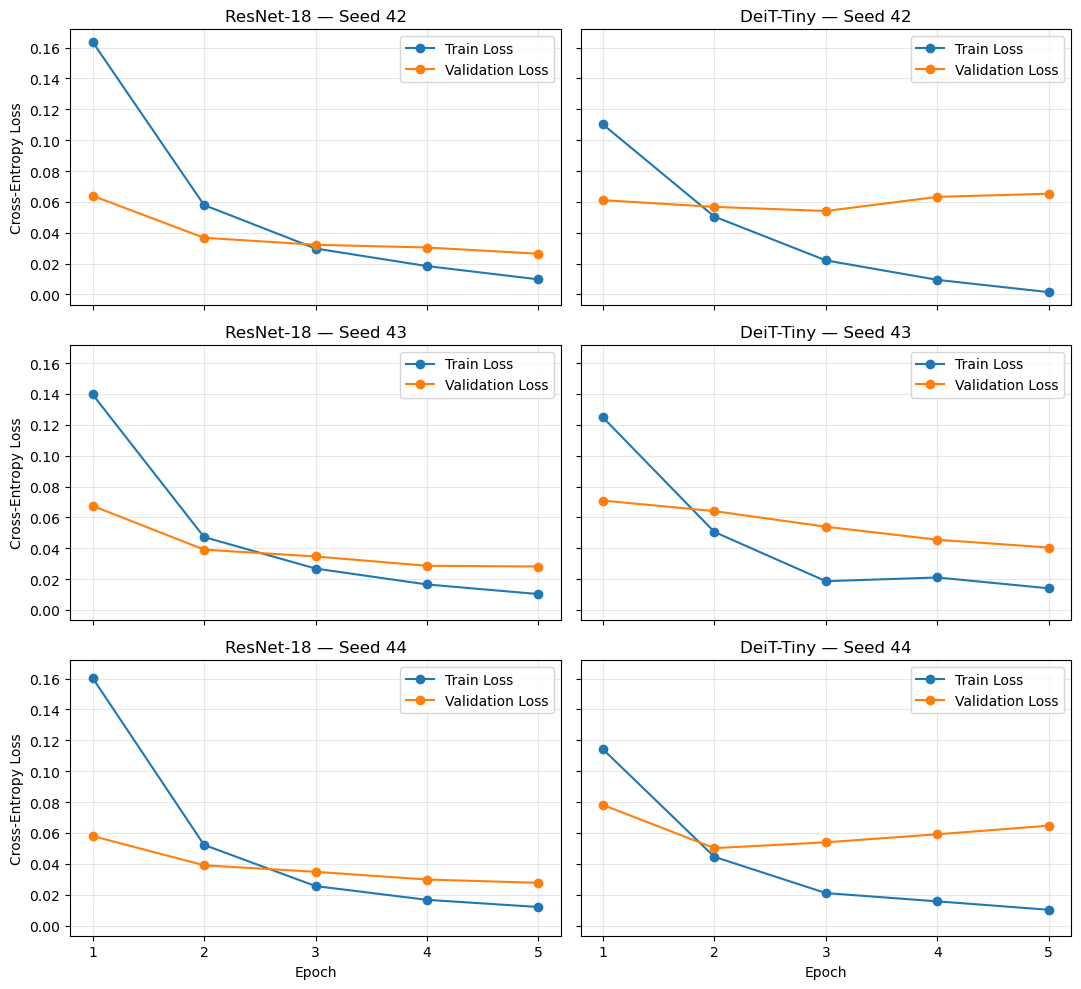

Saved figure: /Users/utmbpblack25/Documents/WorkingProjects/images/training_curves.png


In [ ]:
# Define the two models and create a 3-row x 2-column figure.
plot_models = [("resnet18", "ResNet-18"), ("deit_tiny", "DeiT-Tiny")]

fig, axes = plt.subplots(
    len(cfg.seeds), len(plot_models),
    figsize=(11, 10),
    sharex=True,                              
    sharey=True                                
)

# Plot training and validation loss for each model across all three seeds.
for row_idx, seed in enumerate(cfg.seeds):
    for col_idx, (model_name, model_label) in enumerate(plot_models):
        ax = axes[row_idx, col_idx]           

        # Load the saved training history without rerunning model training.
        history_path = cfg.results_dir / f"{model_name}_seed{seed}_history.csv"
        assert history_path.is_file(), f"History file not found: {history_path}"

        history_df = pd.read_csv(history_path)  # Read epoch, train_loss, val_loss, and val_macro_f1.

        # Plot the two loss curves over the five training epochs.
        ax.plot(
            history_df["epoch"], history_df["train_loss"],
            marker="o", label="Train Loss"
        )                                     

        ax.plot(
            history_df["epoch"], history_df["val_loss"],
            marker="o", label="Validation Loss"
        )                                      

        # Label each panel and use consistent plotting settings.
        ax.set_title(f"{model_label} — Seed {seed}")
        ax.set_xticks(history_df["epoch"])     # Show the five recorded epochs (1–5).
        ax.legend()                           
        ax.grid(True, alpha=0.3)              

        if col_idx == 0:
            ax.set_ylabel("Cross-Entropy Loss")  

        if row_idx == len(cfg.seeds) - 1:
            ax.set_xlabel("Epoch")            

# Adjust figure spacing and save all six panels as one PNG file.
fig.tight_layout()

figure_path = cfg.images_dir / "training_curves.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()                                   
print(f"Saved figure: {figure_path}")


#### 5.3 - Output Interpretation

**1. Results — Training & Validation Loss Trends**

- **ResNet-18:** Training and validation losses decreased across all three seeds, with validation loss approaching a stable level by epoch 5.  

- **DeiT-Tiny:** Training loss generally decreased across all seeds. However, validation loss increased after epoch 3 for seed 42 and after epoch 2 for seed 44, while continuing to decrease for seed 43.

**2. Interpretation & Experimental Rationale**

- ResNet-18 showed more consistent validation loss trends across seeds, while DeiT-Tiny exhibited greater variation in validation loss behavior.  

- The widening gap between training and validation losses for DeiT-Tiny at seeds 42 and 44 suggests possible overfitting.  

- These curves help assess learning behavior but do not determine checkpoint selection, which was based on validation macro-F1.

**3. Limitations & Checks**

- The five-epoch training budget limits conclusions about long-term convergence and overfitting.  

- Loss curves alone do not establish which model generalizes better; final model comparison relies primarily on the multi-seed test macro-F1 results from Section 5.2.  

---  


### 5.4 — Plot Confusion Matrices & Analyze Classification Errors

**Objective**

Visualize confusion matrices for ResNet-18 and DeiT-Tiny across all three seeds and analyze classification errors on the official test set.

**Purpose**

Examine false positives and false negatives, compare sensitivity and specificity, and identify differences in classification error patterns across models and training seeds.

**Procedure**

1. Retrieve the saved test predictions for all six model–seed runs from Section 5.2.  

2. Calculate a confusion matrix for each run using the fixed class order: Normal (0) and Pneumonia (1).  

3. Create one figure with six panels, organized by seed (rows) and model (columns).  

4. Extract true negatives (TN), false positives (FP), false negatives (FN), and true positives (TP) from each confusion matrix.  

5. Summarize error counts, sensitivity, and specificity across all six runs.  

6. Save the figure as `confusion_matrices.png` in `cfg.images_dir`.

**Expected Results**

- **Confusion Matrix Figure:** Six panels (3 seeds × 2 models), displaying classification counts for each run.  

- **Classification Error Summary:** Six rows containing TN, FP, FN, TP, sensitivity, and specificity.  

- **Saved Figure:** `confusion_matrices.png` for subsequent analysis and project documentation.

**Important Distinction**

- Pneumonia (class 1) is the positive class; Normal (class 0) is the negative class.  

- False negatives are Pneumonia images incorrectly classified as Normal, while false positives are Normal images incorrectly classified as Pneumonia.  

- Sensitivity = TP / (TP + FN); Specificity = TN / (TN + FP).  

- All confusion matrices use predictions collected in Section 5.2. No additional inference or model selection is performed.


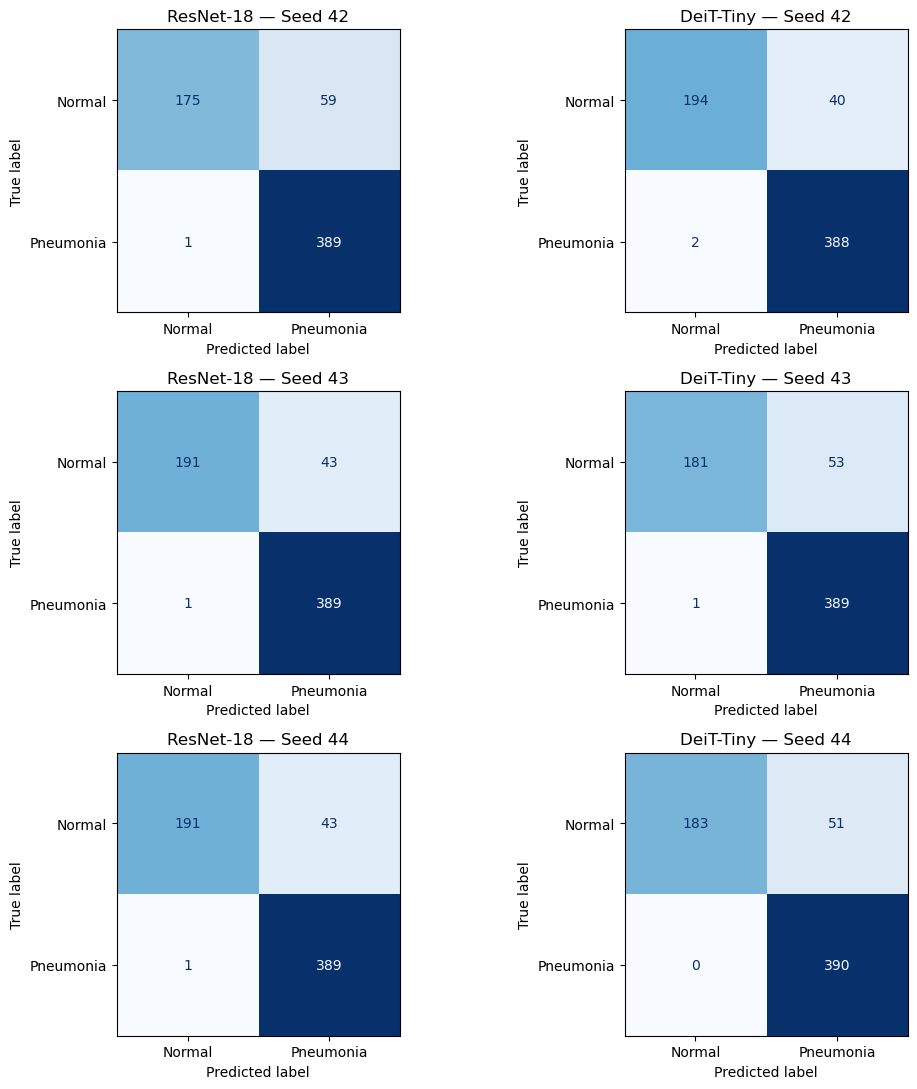

Saved figure: /Users/utmbpblack25/Documents/WorkingProjects/images/confusion_matrices.png

Classification Error Summary:


,Model,Seed,TN,FP,FN,TP,Sensitivity,Specificity
0,resnet18,42,175,59,1,389,0.9974,0.7479
1,deit_tiny,42,194,40,2,388,0.9949,0.8291
2,resnet18,43,191,43,1,389,0.9974,0.8162
3,deit_tiny,43,181,53,1,389,0.9974,0.7735
4,resnet18,44,191,43,1,389,0.9974,0.8162
5,deit_tiny,44,183,51,0,390,1.0000,0.7821


In [ ]:
# Define the models and prepare a 3-row x 2-column figure for all six runs.
plot_models = [("resnet18", "ResNet-18"), ("deit_tiny", "DeiT-Tiny")]
class_names = ["Normal", "Pneumonia"]
error_rows = []                              # Store confusion matrix counts and error rates for each run.

fig, axes = plt.subplots(
    len(cfg.seeds), len(plot_models),
    figsize=(11, 11)
)

# Create a confusion matrix for each model using its saved test predictions.
for row_idx, seed in enumerate(cfg.seeds):
    for col_idx, (model_name, model_label) in enumerate(plot_models):
        ax = axes[row_idx, col_idx]         

        # Retrieve predictions collected during the final test evaluation in Section 5.2.
        predictions = test_predictions[model_name][seed]
        y_true = predictions["y_true"]       
        y_pred = predictions["y_pred"]       # Predicted class labels from the current checkpoint.

        # Calculate confusion matrix counts in the fixed order [Normal, Pneumonia].
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()          # Flatten the 2x2 matrix into TN, FP, FN, and TP.
        assert cm.sum() == len(test_loader.dataset), "Incomplete test predictions."

        # Display actual classification counts with consistent class labels.
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=class_names
        )
        disp.plot(
            ax=ax,                          
            cmap="Blues",                   
            colorbar=False,                 
            values_format="d"               
        )
        ax.set_title(f"{model_label} — Seed {seed}")

        # Record classification errors and their corresponding rates.
        error_rows.append({
            "Model": model_name,
            "Seed": seed,
            "TN": tn,                       # Normal images correctly predicted as Normal.
            "FP": fp,                       # Normal images incorrectly predicted as Pneumonia.
            "FN": fn,                       # Pneumonia images incorrectly predicted as Normal.
            "TP": tp,                       # Pneumonia images correctly predicted as Pneumonia.
            "Sensitivity": tp / (tp + fn),   # Fraction of Pneumonia images correctly identified.
            "Specificity": tn / (tn + fp)    # Fraction of Normal images correctly identified.
        })

# Adjust spacing and save all six confusion matrices as one figure.
fig.tight_layout()

figure_path = cfg.images_dir / "confusion_matrices.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()                                  
print(f"Saved figure: {figure_path}")

# Display a per-seed classification error summary for both models.
error_summary = pd.DataFrame(error_rows)

print("\nClassification Error Summary:")
display(error_summary.round(4))


#### 5.4 - Output Interpretation

**1. Implementation & Verification**

- Six confusion matrices (2 models × 3 seeds) were generated from the saved test predictions, each containing 624 images (234 Normal and 390 Pneumonia).  

- Sensitivity and specificity values matched the results reported in Section 5.2.

**2. Results — Classification Errors**

- **False Negatives:** Both models missed very few Pneumonia cases (0–2 per run), achieving sensitivity between 0.9949 and 1.0000.  

- **False Positives:** More Normal images were incorrectly classified as Pneumonia (40–59 per run), resulting in lower specificity (0.7479–0.8291).  

- **Across Seeds:** DeiT-Tiny had fewer false positives at seed 42, while ResNet-18 had fewer at seeds 43 and 44.

**3. Interpretation & Experimental Rationale**

- Both models identified nearly all Pneumonia cases but showed greater difficulty correctly classifying Normal images.  

- Classification error patterns varied across seeds, with neither model consistently achieving better sensitivity and specificity.  

- Examining all six confusion matrices provides a more complete assessment of classification errors than examining a single seed.

**4. Limitations & Checks**

- The confusion matrices reflect predictions from the fixed classification rule; different decision thresholds could change sensitivity and specificity.  

- All runs were evaluated on the same 624-image test set. These results do not establish performance on external datasets or clinical reliability.

---  


## Part 6 — Discussion & Conclusion

### Overview & Objectives

Interpret the experimental results from Parts 4 and 5 to answer the research question: How do ImageNet-pretrained ResNet-18 and DeiT-Tiny compare in pediatric pneumonia classification under a shared full fine-tuning protocol?

This part integrates multi-seed test performance, training runtimes, learning behavior, and classification errors to discuss the main findings, performance–cost trade-offs, and experimental limitations.

Conclusions are based on the observed results without claiming general superiority of either architecture.

### Workflow & Section Guide

- **6.1 — Main Findings:** Summarize test macro-F1, sensitivity, specificity, validation–test performance differences, and training runtimes. Discuss whether either model demonstrates a meaningful performance or computational advantage.

- **6.2 — Interpretation:** Explain the observed learning behavior, differences between validation and test performance, and classification error patterns. Consider the roles of architecture, pretraining, and optimization without attributing results to a single factor.

- **6.3 — Limitations:** Discuss six key limitations: dataset size and test-set uncertainty, dataset provenance and distribution differences, shared training configuration, model and pretraining differences, limited training repetitions, and limited generalization.

- **6.4 — Conclusion:** Provide a concise final answer to the research question, summarizing the main findings and key limitations.

### Evidence from Previous Parts

- **Part 4:** Validation macro-F1, best checkpoint selection, and training runtimes across three seeds.  

- **Section 5.2:** Final test metrics reported per seed and as mean ± standard deviation.  

- **Section 5.3:** Training and validation loss trends across six training runs.  

- **Section 5.4:** Confusion matrices and classification error patterns across six model–seed runs.

### Expected Outcomes & Role in the Experiment

A concise Discussion & Conclusion consisting of four Markdown sections:

- An evidence-based comparison of ResNet-18 and DeiT-Tiny.  

- An interpretation of learning behavior, classification errors, and computational trade-offs.  

- A clear discussion of experimental limitations.  

- A final conclusion supported by the observed results.

This part completes the study by connecting the experimental findings to the research question. No additional code, experiments, or evaluation metrics are required.  

---  


### 6.1 — Main Findings

**1. Final Test Performance**

- ResNet-18 achieved a mean test macro-F1 of **0.9114 ± 0.0176**, compared with **0.9121 ± 0.0119** for DeiT-Tiny.  

- The mean difference of 0.0007 was very small, with neither model consistently outperforming the other across all three seeds.

**2. Sensitivity, Specificity & Classification Errors**

- Both models achieved high mean sensitivity (0.9974) but lower specificity (approximately 0.79).  

- Each run produced only 0–2 false negatives but 40–59 false positives, indicating greater difficulty classifying Normal images than Pneumonia images.

**3. Validation vs. Test Performance**

- Mean macro-F1 decreased from 0.9884 on validation to 0.9114 on test for ResNet-18, and from 0.9809 to 0.9121 for DeiT-Tiny.  

- Both models performed worse on the held-out test set, although these results alone do not establish the cause of the performance differences.

**4. Computational Cost & Performance–Cost Trade-off**

- Mean training runtimes were approximately 1.37 minutes/run for ResNet-18 and 1.36 minutes/run for DeiT-Tiny on the same hardware.  

- Given the nearly identical test macro-F1 and training runtimes, neither model demonstrated a clear performance–cost advantage under the experimental setup.  

---  


### 6.2 — Interpretation

**1. Learning Behavior**

- ResNet-18 showed consistently decreasing or stabilizing validation loss across all three seeds. In contrast, DeiT-Tiny's validation loss increased during later epochs for seeds 42 and 44, despite decreasing training loss.  

- These trends suggest possible overfitting in some DeiT-Tiny runs, but five epochs are insufficient to establish a definitive conclusion.

**2. Validation–Test Performance Differences**

- High validation macro-F1 did not translate into equally high test macro-F1 for either model.  

- Pneumonia images accounted for approximately 74.2% of the training and validation sets, compared with 62.5% of the test set. Differences in class distribution and dataset provenance may contribute to the observed performance gaps, but their individual effects cannot be determined from this experiment.

**3. Architecture & Experimental Control**

- Although both models followed the same full fine-tuning protocol, they differed in architecture, parameter counts, pretrained weights, and pretraining recipes.  

- Therefore, observed performance differences cannot be attributed solely to convolution versus self-attention. The shared training configuration supports a controlled comparison but does not guarantee optimal settings for either model.  

---   


### 6.3 — Limitations

**1. Small Dataset & Test-Set Uncertainty**

The dataset contains 4,708 training images and 624 test images. Small performance differences should be interpreted cautiously, as no confidence intervals or statistical significance tests were performed.

**2. Dataset Provenance & Distribution Differences**

The training and validation sets were derived from the source development data, while the test set was held out separately. Differences in class proportions and data provenance may affect the observed performance.

**3. Shared Training Configuration**

Both models used the same learning rate, optimizer, batch size, and fixed five-epoch training budget. Hyperparameters were not independently tuned for each architecture.

**4. Model & Pretraining Differences**

ResNet-18 and DeiT-Tiny differ in architecture, model capacity, and pretraining recipes. Therefore, the experiment cannot isolate the effect of architecture alone.

**5. Limited Training Repetitions**

Each model was trained using three random seeds, providing a limited estimate of run-to-run variability. All runs were evaluated on the same fixed test set.

**6. Limited Generalization**

Both models were evaluated only on the official PneumoniaMNIST+ test set, without independent external-hospital validation. These results do not establish clinical reliability or suitability for real-world diagnosis.  

---  


### 6.4 — Conclusion

This study compared ImageNet-pretrained ResNet-18 and DeiT-Tiny for pediatric pneumonia classification under a shared full fine-tuning protocol on PneumoniaMNIST+ 224. Across three training seeds, both models achieved similar mean test macro-F1 scores (0.9114 for ResNet-18 and 0.9121 for DeiT-Tiny), with neither model consistently outperforming the other. Both models identified nearly all Pneumonia cases but showed lower specificity, indicating more difficulty correctly classifying Normal images. Despite differences in validation loss behavior, their test performance and training runtimes were comparable. The findings are limited by the small test set, fixed training configuration, three training seeds, and lack of external validation. Overall, neither model demonstrated a clear advantage under the evaluated conditions, and the results do not establish clinical reliability.  